# Customer Churn Prediction and Analysis Using Machine Learning
### A Data-Driven Approach for Customer Retention
**TM3221 – Data Science for BPM · Group Assignment · University of Moratuwa**

**Research question:** *Which customer characteristics and service-related factors are most strongly associated with customer churn, and how effectively can machine learning models predict churn?*

| Notebook section | Content |
|---|---|
| 0 | Setup and reproducibility |
| 1 | Dataset inspection (before any change) |
| 2 | Data cleaning and outlier treatment |
| 3 | Preparing model inputs: split, imbalance, leakage-safe preprocessing |
| 4–8 | EDA, statistical tests, modelling, interpretation *(added in later phases)* |

> **How to read this notebook.** Each major step has a short box explaining **What** we do, **Why**, **How** the code works, and **What it means**. Reusable functions live in the `src/` folder so this notebook stays readable.

> **Note on wording.** This dataset is observational. We describe **associations** and **predictions**, not causes.

In [ ]:
#@title ▶ Colab setup – run first (recreates the project's src/ folder and dataset)
# Colab only receives this .ipynb file, so this cell rebuilds the rest of the project
# (helper code in src/ and the raw CSV) from the compressed copy below.
# Everything after this cell is identical to telco_churn_analysis.ipynb.
import base64, hashlib, io, os, sys, tarfile
from pathlib import Path

BASE = Path("/content/telco-churn-ml") if "google.colab" in sys.modules else Path.cwd() / "telco-churn-ml-colab"
for sub in ["notebooks", "data/processed", "outputs/figures", "outputs/tables", "outputs/models"]:
    (BASE / sub).mkdir(parents=True, exist_ok=True)

PROJECT_FILES_B64 = """
...
"""
with tarfile.open(fileobj=io.BytesIO(base64.b64decode("".join(PROJECT_FILES_B64.split()))), mode="r:gz") as tar:
    # "data" filter: only plain files inside BASE (and no warning on newer Pythons)
    tar.extractall(BASE, **({"filter": "data"} if hasattr(tarfile, "data_filter") else {}))

csv_hash = hashlib.sha256((BASE / "data/raw/Telco_Customer_Churn.csv").read_bytes()).hexdigest()
assert csv_hash == "901d7d1a43b2206e4a547fc717116695b33648bf3ee33337a634096c8c915ba4", "dataset copy is corrupted"
os.chdir(BASE / "notebooks")          # run the analysis from notebooks/, exactly like the full project
print(f"Project recreated in {BASE} – the analysis below can now run.")

## 0. Setup and reproducibility
**What:** import libraries and our own helper modules, and fix the random seed.

**Why:** a fixed seed (`RANDOM_STATE = 42`) means anyone re-running the notebook gets exactly the same split, models and numbers.

**How:** `src/config.py` holds every path and constant in one place. The notebook lives in `notebooks/`, so we add the project root to Python's search path to import `src`.

In [1]:
# Reload src/ modules automatically when their code changes (avoids stale functions).
# Optional: some environments (e.g. Google Colab on Python 3.13) ship an autoreload
# extension that cannot load, so we skip it there instead of stopping the notebook.
try:
    get_ipython().run_line_magic("load_ext", "autoreload")
    get_ipython().run_line_magic("autoreload", "2")
except Exception as exc:
    print(f"(autoreload not available in this environment - skipped: {exc})")

import os
import sys
from pathlib import Path

# ---------------------------------------------------------------------------
# Find the project folder (the folder that contains src/config.py).
# * On your own computer the notebook runs from telco-churn-ml/notebooks/.
# * Google Colab always starts in /content, so there we look for the uploaded
#   project folder, mounting Google Drive if necessary.
# ---------------------------------------------------------------------------
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # Change these if you put the project folder somewhere else
    colab_candidates = [Path("/content/telco-churn-ml"), Path("/content/drive/MyDrive/telco-churn-ml")]
    if not any((c / "src" / "config.py").exists() for c in colab_candidates):
        from google.colab import drive
        drive.mount("/content/drive")
    for candidate in colab_candidates:
        if (candidate / "src" / "config.py").exists():
            os.chdir(candidate / "notebooks")
            break


def find_project_root(start):
    """Walk up from `start` until a folder containing src/config.py is found."""
    for folder in [start, *start.parents]:
        if (folder / "src" / "config.py").exists():
            return folder
    raise FileNotFoundError(
        "Project folder not found. Upload the WHOLE telco-churn-ml folder (with src/, data/, notebooks/) "
        "and, in Colab, put it at /content/telco-churn-ml or MyDrive/telco-churn-ml.")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print(f"Project folder: {PROJECT_ROOT}")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

from src import config
from src import data_cleaning as dc
from src import eda_plots as ep
from src import modeling as md

ep.set_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
config.TABLE_DIR.mkdir(parents=True, exist_ok=True)

print(f"Python       {sys.version.split()[0]}")
print(f"pandas       {pd.__version__}")
print(f"numpy        {np.__version__}")
print(f"scikit-learn {sklearn.__version__}")
print(f"matplotlib   {matplotlib.__version__}")
print(f"Random state {config.RANDOM_STATE}")

Project folder: /Users/avishka/Documents/ML Project 2/telco-churn-ml


Python       3.10.19
pandas       2.2.3
numpy        1.26.4
scikit-learn 1.6.1
matplotlib   3.9.4
Random state 42


## 1. Dataset inspection – before changing anything
**What:** load the raw CSV and record every property and problem *before* modifying the data.

**Why:** cleaning decisions must be based on evidence. Writing problems down first also lets us show the lecturer exactly what changed and why.

**How:** we read the file with `dtype=str` and `keep_default_na=False`. Every value stays as text, so blanks (`" "`), invalid tokens (`"INVALID_VAL"`) and codes such as `-99` are visible instead of being silently converted.

### 1.1 Load the raw file and confirm it is unchanged

In [2]:
raw = dc.load_raw()
checksum_ok = dc.file_sha256(config.RAW_DATA_PATH) == config.RAW_DATA_SHA256
print(f"Raw file shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print(f"Raw file unchanged (SHA-256 matches): {checksum_ok}")
assert checksum_ok, "The raw data file has been modified!"
raw.head()

Raw file shape: 7,073 rows x 21 columns
Raw file unchanged (SHA-256 matches): True


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1.0,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34.0,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2.0,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45.0,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3,1840.75,No
4,9237-HQITU,Female,0,No,No,2.0,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.7,151.65,Yes


### 1.2 Column types as pandas would see them by default
With a normal `pd.read_csv()`, `TotalCharges` is read as **text (object)** even though it should be numeric. Some values in it are not numbers.

In [3]:
naive = pd.read_csv(config.RAW_DATA_PATH)
naive.dtypes.to_frame("default pandas dtype").T

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
default pandas dtype,object,object,int64,object,object,float64,object,object,object,object,object,object,object,object,object,object,object,object,float64,object,object


### 1.3 Target variable: `Churn`

In [4]:
target_counts = raw[config.TARGET].value_counts()
pd.DataFrame({"customers": target_counts,
              "percent": (target_counts / len(raw) * 100).round(1)})

,customers,percent
Churn,,
No,5192,73.4
Yes,1881,26.6


### 1.4 Missing values: what pandas reports vs what is really there

In [5]:
missing_table = dc.missing_value_table(raw)
missing_table.to_csv(config.TABLE_DIR / "t01_raw_missing_values.csv", index=False)
n_cells = raw.shape[0] * raw.shape[1]
n_missing = missing_table["total_missing_or_invalid_text"].sum()
print(f"Missing or invalid text entries: {n_missing} = {n_missing / n_cells:.2%} of all {n_cells:,} data points "
      "(impossible numeric values are added in Section 1.9)")
missing_table[missing_table[["pandas_isnull_default", "total_missing_or_invalid_text"]].sum(axis=1) > 0]

Missing or invalid text entries: 193 = 0.13% of all 148,533 data points (impossible numeric values are added in Section 1.9)


,column,pandas_isnull_default,blank_or_whitespace,invalid_label,non_numeric_text,total_missing_or_invalid_text,pct_of_rows
1,gender,6,0,15,0,15,0.212074
5,tenure,40,40,0,0,40,0.565531
15,Contract,35,35,0,0,35,0.494840
18,MonthlyCharges,80,80,0,0,80,1.131062
19,TotalCharges,0,11,0,12,23,0.325180


**Interpretation**
- `df.isnull().sum()` under-reports the problem in this file:
  - It finds **0** problems in `TotalCharges`, which actually has 11 blank strings and 12 `INVALID_VAL` entries.
  - For `gender` it finds only the 6 `"N/A"` values (pandas treats that word as missing). It misses `"Unknown"` and `"OtherXYZ"`.
- **Lesson for the presentation:** always inspect the actual values, not just `isnull()`.

### 1.5 Unexpected categorical labels

In [6]:
for col in config.CATEGORICAL_FEATURES + [config.TARGET]:
    counts = raw[col].replace("", "<blank>").value_counts()
    unexpected = counts[~counts.index.isin(config.VALID_CATEGORIES[col])]
    flag = "  <-- unexpected: " + str(unexpected.to_dict()) if len(unexpected) else ""
    print(f"{col:17s} {counts.to_dict()}{flag}")

gender            {'Male': 3560, 'Female': 3498, 'Unknown': 7, 'N/A': 6, 'OtherXYZ': 2}  <-- unexpected: {'Unknown': 7, 'N/A': 6, 'OtherXYZ': 2}
SeniorCitizen     {'0': 5926, '1': 1147}
Partner           {'No': 3656, 'Yes': 3417}
Dependents        {'No': 4952, 'Yes': 2121}
PhoneService      {'Yes': 6389, 'No': 684}
MultipleLines     {'No': 3404, 'Yes': 2985, 'No phone service': 684}
InternetService   {'Fiber optic': 3111, 'DSL': 2430, 'No': 1532}
OnlineSecurity    {'No': 3515, 'Yes': 2026, 'No internet service': 1532}
OnlineBackup      {'No': 3102, 'Yes': 2439, 'No internet service': 1532}
DeviceProtection  {'No': 3109, 'Yes': 2432, 'No internet service': 1532}
TechSupport       {'No': 3490, 'Yes': 2051, 'No internet service': 1532}
StreamingTV       {'No': 2822, 'Yes': 2719, 'No internet service': 1532}
StreamingMovies   {'No': 2801, 'Yes': 2740, 'No internet service': 1532}
Contract          {'Month-to-month': 3881, 'Two year': 1693, 'One year': 1464, '<blank>': 35}  <-- unexpected: 

### 1.6 Numeric columns: impossible values
We convert the three numeric columns to numbers, temporarily and only for inspection. Anything that is not a number becomes NaN.

In [7]:
raw_numeric = raw[config.NUMERIC_FEATURES].apply(lambda s: pd.to_numeric(s.str.strip(), errors="coerce"))
raw_numeric.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
tenure,7033.0,33.15,37.20,-99.00,9.0,29.00,55.0,988.49
MonthlyCharges,6993.0,76.22,310.89,18.25,35.5,70.35,89.9,9959.83
TotalCharges,7050.0,2281.87,2266.17,18.80,400.5,1397.10,3787.9,8684.80


**Interpretation**
- `tenure` (months with the company) ranges from **−99 to 988.5**. Neither is possible:
  - −99 is a typical "missing" code.
  - 988.5 months would be over 80 years, and tenure should be a whole number.
- `MonthlyCharges` reaches **9,959.83**, while the typical bill is about 18–119 USD.

These are **data-entry errors**, not genuine extreme customers. The audit below quantifies them.

### 1.7 Duplicates and identifiers

In [8]:
n_exact_dup = raw.duplicated().sum()
n_id_dup = raw[config.ID_COL].duplicated().sum()
dup_ids = raw.loc[raw[config.ID_COL].duplicated(keep=False), config.ID_COL].unique()
dups_identical = all(raw[raw[config.ID_COL] == i].drop_duplicates().shape[0] == 1 for i in dup_ids)
print(f"Exact duplicate rows (extra copies): {n_exact_dup}")
print(f"Repeated customerIDs:                {n_id_dup}")
print(f"Every repeated ID is an exact copy:  {dups_identical}")
print(f"Unique customers:                    {raw[config.ID_COL].nunique():,}")

Exact duplicate rows (extra copies): 30
Repeated customerIDs:                30
Every repeated ID is an exact copy:  True
Unique customers:                    7,043


### 1.8 Logical consistency checks
Customers without internet should show "No internet service" for all six add-ons. Customers without phone service should show "No phone service" for `MultipleLines`.

In [9]:
no_internet = raw["InternetService"] == "No"
addon_ok = (raw.loc[no_internet, config.ADDON_SERVICES] == "No internet service").all(axis=1).all()
no_phone = raw["PhoneService"] == "No"
lines_ok = (raw.loc[no_phone, "MultipleLines"] == "No phone service").all()
print(f"No-internet customers have consistent add-on values: {addon_ok}")
print(f"No-phone customers have consistent MultipleLines:    {lines_ok}")

# Billing identity: TotalCharges should be roughly tenure x MonthlyCharges
t, m, c = raw_numeric["tenure"], raw_numeric["MonthlyCharges"], raw_numeric["TotalCharges"]
valid = (t >= 1) & (t == t.round()) & (m <= config.MAX_PLAUSIBLE_MONTHLY_CHARGE) & c.notna()
ratio = c[valid] / (t[valid] * m[valid])
print(f"TotalCharges / (tenure x MonthlyCharges): median {ratio.median():.2f}, "
      f"middle 98% between {ratio.quantile(0.01):.2f} and {ratio.quantile(0.99):.2f}")

No-internet customers have consistent add-on values: True
No-phone customers have consistent MultipleLines:    True


TotalCharges / (tenure x MonthlyCharges): median 1.00, middle 98% between 0.85 and 1.16


**Interpretation:** the service fields are internally consistent.
- `TotalCharges` is almost exactly `tenure × MonthlyCharges`. The small deviations come from price changes over a customer's lifetime.
- This identity has two consequences:
  1. We can **repair** a corrupted value in one of the three columns using the other two.
  2. `TotalCharges` largely **duplicates** information in `tenure` and `MonthlyCharges`, so we expect multicollinearity (checked in the statistical analysis section).

### 1.9 Data-quality audit summary

In [10]:
audit = dc.audit_dataset(raw)
audit.to_csv(config.TABLE_DIR / "t02_data_quality_audit.csv", index=False)
audit

,check,column,count,example,planned_treatment
0,Exact duplicate rows,all,30,same customerID and identical values,Remove extra copies
1,Repeated customerID,customerID,30,every repeated ID is an exact duplicate row,Resolved by removing exact duplicates
2,"Identical profile, different customerID",all,20,e.g. new customers with only a basic phone plan,Keep - genuinely different customers
3,Invalid / blank category,gender,15,"{'Unknown': 7, 'N/A': 6, 'OtherXYZ': 2}",Set to missing
4,Invalid / blank category,Contract,35,{'<blank>': 35},Set to missing
5,Blank value,tenure,40,'',Set to missing
6,Negative sentinel value,tenure,10,[-99.0],Set to missing
7,Impossible non-integer value,tenure,10,545.8 to 988.5 months,Set to missing
8,Zero tenure (new customer),tenure,11,0,Keep - valid new customers
9,Blank value,MonthlyCharges,50,'',Set to missing


All problem values (blank, invalid text/label, impossible): 223 = 0.15% of all data points


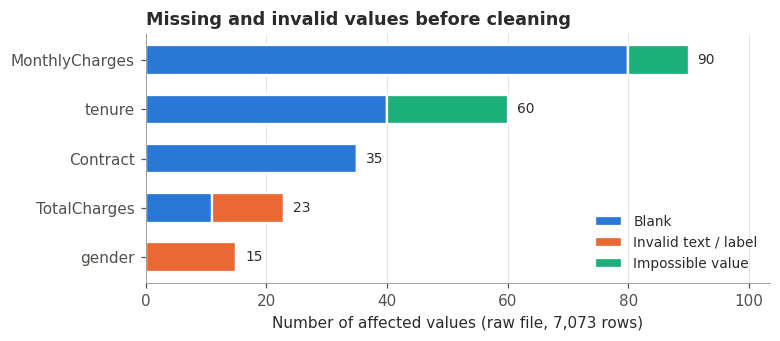

In [11]:
issue_counts = dc.issue_counts_by_type(raw)
issue_counts.to_csv(config.TABLE_DIR / "t03_issue_counts_by_type.csv")
n_problem = int(issue_counts.to_numpy().sum())
print(f"All problem values (blank, invalid text/label, impossible): {n_problem} = "
      f"{n_problem / (raw.shape[0] * raw.shape[1]):.2%} of all data points")
fig = ep.plot_data_issues(issue_counts)
ep.save_fig(fig, "fig01_missing_invalid_before_cleaning.png")
plt.show()

**Figure 1 – interpretation**
- Five of the 21 columns contain problem values. `MonthlyCharges` and `tenure` are the most affected.
- These counts come from the raw file (7,073 rows), so they include the 30 duplicated rows. Every duplicated row also has a blank `MonthlyCharges`.
- Even in total, the affected values are a small share of the data. That makes **repairing or imputing them preferable to deleting customers**.

## 2. Data cleaning and outlier treatment
**What:** fix the problems found above using clear, documented rules.

**Why these rules are safe before the train/test split:** each rule looks at **one row at a time** and learns nothing from other customers (no averages, medians or modes). It therefore cannot leak information from the future test set into training. Any statistical imputation is done later, **inside the model Pipeline, using training data only**.

| Rule | Applies to | Action |
|---|---|---|
| R1 | 30 exact duplicate rows | Remove the extra copies |
| R2 | Invalid or blank labels (`gender`, `Contract`) | Set to missing → imputed in the Pipeline |
| R3 | `tenure` negative (−99) or non-integer (545–988) | Set to missing, then repair (R5) |
| R4 | `MonthlyCharges` > 200 USD (values of 5,765–9,960) | Set to missing, then repair (R5) |
| R4b | Blank `TotalCharges` where tenure = 0 | Set to 0: a brand-new customer has not been billed yet |
| R5 | One missing value among tenure / MonthlyCharges / TotalCharges | Rebuild it from the other two using TotalCharges ≈ tenure × MonthlyCharges |
| R6 | `SeniorCitizen` coded 0/1 | Recode to No/Yes like the other binary columns |

### 2.1 Is the repair rule (R5) accurate enough?
We test the identity on the customers whose three values are all valid. We then compare its error with simple median imputation.

In [12]:
recon = dc.reconstruction_accuracy(raw)
recon.to_csv(config.TABLE_DIR / "t04_reconstruction_accuracy.csv", index=False)
recon.round(2)

,value_repaired,rows_checked,method,repair_mean_abs_error,repair_median_abs_pct_error,median_imputation_mean_abs_error,median_imputation_median_abs_pct_error
0,TotalCharges,6900,tenure x MonthlyCharges,44.90,2.0,1774.94,74.50
1,tenure,6900,round(TotalCharges / MonthlyCharges),0.67,0.0,21.73,57.35
2,MonthlyCharges,6900,TotalCharges / tenure,1.75,2.0,25.85,29.27


**Interpretation:** rebuilding a value from the other two is far more accurate than filling in the median.

| Value | Typical error when rebuilt | Typical error with median imputation |
|---|---|---|
| TotalCharges | about 2% | about 75% |
| tenure | under 1 month on average | about 22 months on average |
| MonthlyCharges | under 2 USD on average | about 26 USD on average |

The rule uses only the customer's own row, so it is leakage-free.

### 2.2 Apply the cleaning rules

In [13]:
clean, change_log = dc.clean_dataset(raw)
dc.validate_clean(clean)          # raises an error if any rule is violated
print(f"Rows: {len(raw):,} -> {len(clean):,} (removed {len(raw) - len(clean)} exact duplicates)")

change_summary = (change_log.groupby(["column", "rule"]).size()
                  .rename("values_changed").reset_index())
change_summary.to_csv(config.TABLE_DIR / "t05_cleaning_summary.csv", index=False)
change_log.to_csv(config.TABLE_DIR / "t06_cleaning_change_log.csv", index=False)
change_summary

Rows: 7,073 -> 7,043 (removed 30 exact duplicates)


,column,rule,values_changed
0,Contract,invalid/blank label -> missing,35
1,MonthlyCharges,invalid -> TotalCharges / tenure,60
2,TotalCharges,blank with tenure 0 -> 0,11
3,TotalCharges,invalid -> tenure x MonthlyCharges,12
4,gender,invalid/blank label -> missing,15
5,tenure,invalid -> round(TotalCharges / MonthlyCharges),60


In [14]:
remaining = clean.isna().sum()
print("Values still missing after the row-wise rules (to be imputed inside the Pipeline):")
print(remaining[remaining > 0].to_string())

Values still missing after the row-wise rules (to be imputed inside the Pipeline):
gender      15
Contract    35


**Interpretation**
- No customer had more than one of the three numeric values corrupted, so **every numeric problem could be repaired**.
- Only 15 `gender` and 35 `Contract` values (0.7% of customers) remain missing. They are filled with the most frequent category inside the Pipeline, learned from the training data only.
- `change_log` (saved as `t06_cleaning_change_log.csv`) lists every single change: customer, column, old value, new value and rule.

### 2.3 Are the affected customers different? (missingness check)
If errors were concentrated among churners, repairing them could bias the analysis. We compare churn rates.

In [15]:
affected_ids = set(change_log.loc[~change_log["rule"].str.startswith("blank with tenure 0"), "customerID"])
clean["_affected"] = clean[config.ID_COL].isin(affected_ids)
miss_vs_churn = (clean.groupby("_affected")[config.TARGET]
                 .agg(customers="size", churn_rate=lambda s: (s == "Yes").mean() * 100)
                 .rename(index={False: "Not affected", True: "Had a repaired/missing value"}).round(1))
from scipy.stats import chi2_contingency
chi2, p_value, _, _ = chi2_contingency(pd.crosstab(clean["_affected"], clean[config.TARGET]))
clean = clean.drop(columns="_affected")
miss_vs_churn["chi2_p_value"] = p_value
miss_vs_churn.to_csv(config.TABLE_DIR / "t07_missingness_vs_churn.csv")
print(f"Chi-square test of independence (affected vs churn): chi2 = {chi2:.2f}, p = {p_value:.3f}")
miss_vs_churn

Chi-square test of independence (affected vs churn): chi2 = 2.23, p = 0.135


,customers,churn_rate,chi2_p_value
_affected,,,
Not affected,6863,26.4,0.135302
Had a repaired/missing value,180,31.7,0.135302


**Interpretation**
- The 180 affected customers churned at **31.7%**, compared with **26.4%** for the rest.
- The chi-square test does **not** find this difference statistically significant (p ≈ 0.14). With only 180 affected customers, though, a real difference of this size cannot be ruled out either.
- **Practical conclusion:** the affected customers are only 2.6% of the data, and their values were repaired or imputed rather than deleted. Any bias from this is therefore very small.
- We report the gap openly instead of claiming the errors are "completely random".

### 2.4 Outlier detection after cleaning (IQR rule)
**What:** count values outside the Tukey fences (Q1 − 1.5×IQR, Q3 + 1.5×IQR).

**Why we do not delete or winsorise automatically:** a value far from the others is only a problem if it is *wrong*. The impossible values were errors and were handled by R3–R5. Legitimate extremes, such as a loyal 72-month customer with a large total bill, are real behaviour and important for predicting churn.

In [16]:
outliers = dc.iqr_outlier_table(clean)
outliers.to_csv(config.TABLE_DIR / "t08_iqr_outliers_after_cleaning.csv", index=False)
outliers.round(2)

,column,n,min,Q1,median,Q3,max,lower_fence,upper_fence,n_below,n_above,skewness
0,tenure,7043,0.00,9.00,29.00,55.0,72.00,-60.00,124.00,0,0,0.24
1,MonthlyCharges,7043,18.25,35.50,70.35,89.9,118.75,-46.10,171.50,0,0,-0.22
2,TotalCharges,7043,0.00,398.55,1394.40,3786.6,8684.80,-4683.52,8868.67,0,0,0.96


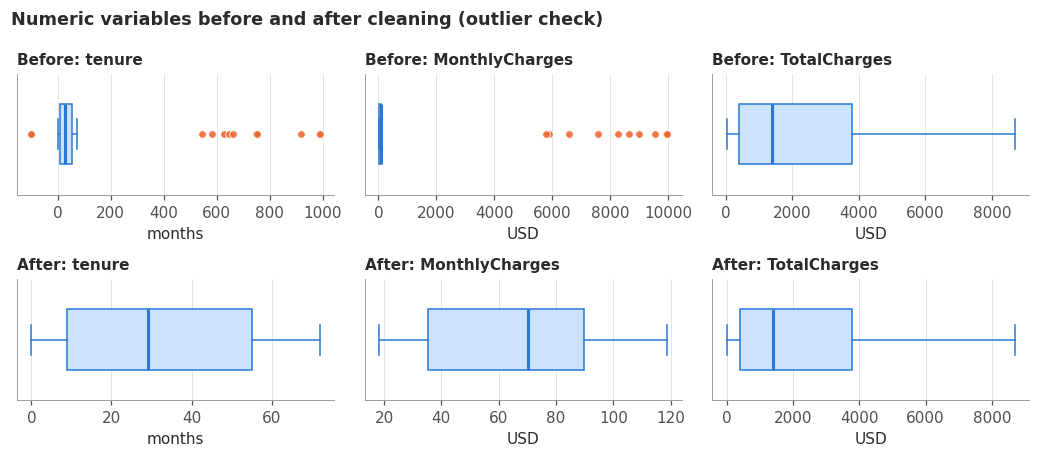

In [17]:
fig = ep.plot_before_after_boxplots(raw_numeric, clean)
ep.save_fig(fig, "fig02_boxplots_before_after_cleaning.png")
plt.show()

**Figure 2 – interpretation**
- **Before cleaning**, a few impossible values stretch the axes so much that the real distribution is squashed into a thin box.
- **After cleaning**:
  - No values lie outside the IQR fences for any of the three variables.
  - `TotalCharges` is right-skewed (many new, low-spending customers; fewer long-tenure, high-spending ones), but every value is plausible.
- **Decision:** keep all values, with no deletion or winsorisation. Tree models are insensitive to skew, and logistic regression uses standardised inputs.

### 2.5 Data dictionary

In [18]:
data_dictionary = dc.build_data_dictionary(raw, clean)
data_dictionary.to_csv(config.TABLE_DIR / "t09_data_dictionary.csv", index=False)
data_dictionary

,variable,group,type_after_cleaning,values_after_cleaning,description,relevance_to_churn,missing_after_cleaning
0,customerID,Identifier,Text (ID),"7,043 unique codes",Unique customer code.,Not a predictor - removed from model features.,0
1,gender,Demographic,Binary categorical,Female / Male,Customer gender (Female / Male).,Checks whether churn differs by gender; also a...,15
2,SeniorCitizen,Demographic,Binary categorical,No / Yes,"Whether the customer is 65 or older (0 = No, 1...",Older customers may have different service needs.,0
3,Partner,Demographic,Binary categorical,No / Yes,Whether the customer has a partner.,Household ties may relate to account stability.,0
4,Dependents,Demographic,Binary categorical,No / Yes,Whether the customer has dependents.,Family accounts may be harder to move.,0
5,tenure,Account,Numeric (whole months),0.00 to 72.00,Number of months the customer has stayed with ...,Measures customer relationship length - a key ...,0
6,PhoneService,Service,Binary categorical,No / Yes,Whether the customer has a phone service.,Part of the subscribed service bundle.,0
7,MultipleLines,Service,Nominal categorical,No / No phone service / Yes,Whether the customer has multiple phone lines.,Indicates depth of phone subscription.,0
8,InternetService,Service,Nominal categorical,DSL / Fiber optic / No,"Internet type: DSL, Fiber optic or No internet.",Service type may relate to price and satisfact...,0
9,OnlineSecurity,Add-on,Nominal categorical,No / No internet service / Yes,Online security add-on subscribed.,Add-ons may increase engagement and switching ...,0


### 2.6 Save the cleaned dataset
The original file in `data/raw/` is never modified. The cleaned version keeps the original column names and labels (useful for EDA). The 50 remaining categorical gaps are left as empty cells for the Pipeline to impute.

In [19]:
config.PROCESSED_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
clean.to_csv(config.PROCESSED_DATA_PATH, index=False)
print(f"Saved {config.PROCESSED_DATA_PATH.relative_to(PROJECT_ROOT)}  shape={clean.shape}")
assert dc.file_sha256(config.RAW_DATA_PATH) == config.RAW_DATA_SHA256  # raw still untouched

Saved data/processed/telco_churn_clean.csv  shape=(7043, 21)


## 3. Preparing model inputs
### 3.1 Features and target
**What:** separate the predictors (X) from the outcome (y, 1 = churned).

**Two deliberate choices:**
1. **`customerID` is dropped.** It is an arbitrary code with no meaning for churn. A model could only memorise it, which would not generalise.
2. **"No internet service" → "No" and "No phone service" → "No" for modelling.** Whether a customer has internet is already recorded in `InternetService`. Keeping the extra label would create six identical dummy columns (perfect redundancy). EDA still uses the original labels.

In [20]:
X, y = dc.prepare_model_data(clean)
assert config.ID_COL not in X.columns
print(f"X: {X.shape[0]:,} customers x {X.shape[1]} features | y: churn rate {y.mean():.1%}")
X.head(3)

X: 7,043 customers x 19 features | y: churn rate 26.5%


,tenure,MonthlyCharges,TotalCharges,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod
0,1.0,29.85,29.85,Female,No,Yes,No,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check
1,34.0,56.95,1889.50,Male,No,No,No,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check
2,2.0,53.85,108.15,Male,No,No,No,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check


### 3.2 Stratified 80/20 train/test split
**What:** hold back 20% of customers as a **test set** that no model sees until final evaluation.

**Why stratified:** it keeps the same churn percentage in both sets, so the test set is representative.

**Why only once:** if we kept checking test scores while tuning, the test set would quietly become part of training. Its score would then be over-optimistic.

In [21]:
X_train, X_test, y_train, y_test = md.split_data(X, y)

split_summary = pd.DataFrame({
    "customers": [len(y_train), len(y_test)],
    "churned": [int(y_train.sum()), int(y_test.sum())],
    "churn_rate_%": [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)],
}, index=["train (80%)", "test (20%)"])
split_summary.to_csv(config.TABLE_DIR / "t10_split_summary.csv")

# Leakage checks
assert set(X_train.index).isdisjoint(X_test.index), "train and test overlap!"
assert len(X_train) + len(X_test) == len(X)
split_summary

,customers,churned,churn_rate_%
train (80%),5634,1495,26.54
test (20%),1409,374,26.54


### 3.3 Class imbalance
About **26.5%** of customers churned, so the classes are moderately imbalanced (roughly 1 churner for every 3 customers who stay).

**Why it matters:** a useless model that predicts "No churn" for everyone would still be **73.5% accurate** while catching zero churners. We will therefore judge models mainly on ROC-AUC, recall, precision and F1, and include this "always No" model as a `DummyClassifier` baseline.

**How we will handle it:** we test `class_weight="balanced"` as a model option. It makes each churner count about 3× more during training, so the model cannot ignore the minority class.
- **We do not use SMOTE.** Class weighting achieves the rebalancing without inventing synthetic customers.
- If SMOTE were used, it would have to be applied **inside** the cross-validation pipeline (to training folds only), **never before splitting**. Otherwise synthetic copies of test customers leak into training.

### 3.4 Leakage-safe preprocessing pipeline
**What:** a `ColumnTransformer` prepares each column type:

| Column type | Step 1 | Step 2 |
|---|---|---|
| Numeric (tenure, MonthlyCharges, TotalCharges) | Median imputation (safety net) | Standardisation (mean 0, SD 1) |
| Categorical (16 columns) | Most-frequent imputation | One-hot encoding |

**Why one-hot, not label encoding:** label encoding would turn e.g. PaymentMethod into 0/1/2/3. That implies a false order ("mailed check > bank transfer") which a linear model would take literally. One-hot encoding creates a separate Yes/No column for each category.

**Why inside a Pipeline:** the median, the most frequent value, the mean and SD for scaling, and the list of categories are all **learned from the data passed to `fit`**. We fit on training data only, and during cross-validation the Pipeline is re-fitted on each training fold. The test set therefore never influences preprocessing.

In [22]:
preprocessor = md.build_preprocessor()
preprocessor.fit(X_train)            # learns ONLY from the training set

feature_names = preprocessor.get_feature_names_out()
X_train_prepared = preprocessor.transform(X_train)
print(f"Prepared training matrix: {X_train_prepared.shape[0]:,} rows x {X_train_prepared.shape[1]} columns")

num_pipe = preprocessor.named_transformers_["num"]
cat_pipe = preprocessor.named_transformers_["cat"]
print("\nLearned from TRAINING data only:")
print("  numeric medians :", dict(zip(config.NUMERIC_FEATURES, num_pipe.named_steps["impute"].statistics_.round(2))))
print("  scaler means    :", dict(zip(config.NUMERIC_FEATURES, num_pipe.named_steps["scale"].mean_.round(2))))
modes = dict(zip(config.CATEGORICAL_FEATURES, cat_pipe.named_steps["impute"].statistics_))
print("  imputation mode :", {k: modes[k] for k in ["gender", "Contract"]})
imputation_values = pd.DataFrame(
    [{"column": col, "type": "numeric", "strategy": "median", "learned_value": round(float(v), 2),
      "missing_in_clean_data": int(clean[col].isna().sum())}
     for col, v in zip(config.NUMERIC_FEATURES, num_pipe.named_steps["impute"].statistics_)] +
    [{"column": col, "type": "categorical", "strategy": "most frequent", "learned_value": modes[col],
      "missing_in_clean_data": int(clean[col].isna().sum())} for col in config.CATEGORICAL_FEATURES])
imputation_values.to_csv(config.TABLE_DIR / "t47_imputation_values.csv", index=False)
print("\nModel feature columns:")
print(list(feature_names))

Prepared training matrix: 5,634 rows x 26 columns

Learned from TRAINING data only:
  numeric medians : {'tenure': 29.0, 'MonthlyCharges': 70.47, 'TotalCharges': 1394.0}
  scaler means    : {'tenure': 32.48, 'MonthlyCharges': 64.93, 'TotalCharges': 2299.39}
  imputation mode : {'gender': 'Male', 'Contract': 'Month-to-month'}

Model feature columns:
['tenure', 'MonthlyCharges', 'TotalCharges', 'gender_Male', 'SeniorCitizen_Yes', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_Yes', 'InternetService_DSL', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_Yes', 'OnlineBackup_Yes', 'DeviceProtection_Yes', 'TechSupport_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes', 'Contract_Month-to-month', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Bank transfer (automatic)', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


**Section 3 summary**
- **Data:** 7,043 customers with 19 predictors, which become 26 model columns after one-hot encoding.
- **Split:**
  - 5,634 customers in training and 1,409 in testing, with an identical churn rate (~26.5%).
  - Train and test do not overlap, and `customerID` is excluded.
- **Leakage safety:** every learned preprocessing value comes from the training set only. The same `build_preprocessor()` is reused inside every model Pipeline in the modelling section.

## 4. Exploratory Data Analysis (EDA)
**What:** describe the customers and find out which characteristics are associated with churn.

**Why:** EDA lets us:
- understand the data before modelling
- generate hypotheses (e.g. "month-to-month customers churn more")
- check later whether the models' important features make business sense

**How:**
- We use the cleaned data with its **original labels** (e.g. "No internet service").
- **Churn rate** = churned customers ÷ customers in a group.
- Every chart shows group sizes (n), so small groups are not over-interpreted.
- Three helper columns are added **for EDA only** (they are never model inputs):
  - `churn_flag` (0/1)
  - `tenure_group`: `pd.cut` binning into 0–12, 13–24, 25–48 and 49–72 months, as in the Pandas tutorial
  - `n_addons`: the number of internet add-on services

> **Associations, not causes.** A higher churn rate in a group shows that two things occur together. It does not prove that one causes the other. Groups often differ in several ways at once, e.g. fiber customers also pay more.

> **Leakage note:** EDA describes all 7,043 customers. No modelling decision (such as dropping features) is based on it, so it does not leak test information into the models.

In [23]:
eda = ep.add_eda_columns(clean)
overall_churn = eda["churn_flag"].mean() * 100
print(f"Customers: {len(eda):,} | churned: {eda['churn_flag'].sum():,} | overall churn rate: {overall_churn:.1f}%")

Customers: 7,043 | churned: 1,869 | overall churn rate: 26.5%


### 4.1 Target variable: churn distribution and percentage

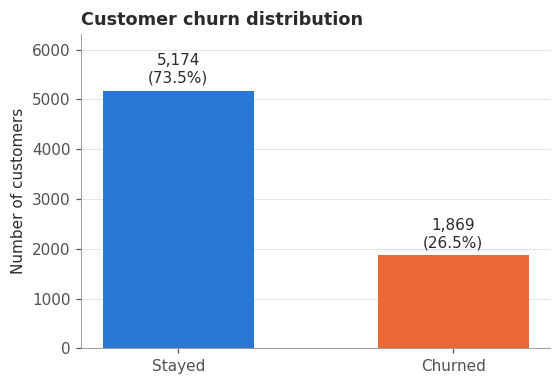

In [24]:
fig = ep.plot_churn_distribution(eda)
ep.save_fig(fig, "fig03_churn_distribution.png")
plt.show()

**Figure 3 – interpretation**
- **5,174 customers (73.5%) stayed and 1,869 (26.5%) churned**, roughly 2.8 stayers for every churner.
- **Relevance to prediction:**
  - The classes are moderately imbalanced. Predicting "No" for everyone already gives 73.5% accuracy, so **accuracy alone cannot judge a model**.
  - We therefore also report recall, precision, F1 and ROC-AUC, and use class weighting.

### 4.2 Summary statistics of numeric variables

In [25]:
numeric_summary = pd.concat(
    {"All": eda[config.NUMERIC_FEATURES].describe().T,
     "Stayed": eda.loc[eda["churn_flag"] == 0, config.NUMERIC_FEATURES].describe().T,
     "Churned": eda.loc[eda["churn_flag"] == 1, config.NUMERIC_FEATURES].describe().T},
    names=["group", "variable"])[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
numeric_summary.to_csv(config.TABLE_DIR / "t11_numeric_summary_by_churn.csv")
numeric_summary.round(1)

count    mean     std   min    25%     50%     75%     max
group   variable                                                                   
All     tenure          7043.0    32.4    24.6   0.0    9.0    29.0    55.0    72.0
        MonthlyCharges  7043.0    64.8    30.1  18.2   35.5    70.4    89.9   118.8
        TotalCharges    7043.0  2279.8  2266.9   0.0  398.6  1394.4  3786.6  8684.8
Stayed  tenure          5174.0    37.6    24.1   0.0   15.0    38.0    61.0    72.0
        MonthlyCharges  5174.0    61.3    31.1  18.2   25.1    64.4    88.4   118.8
        TotalCharges    5174.0  2550.0  2330.0   0.0  572.9  1679.5  4263.4  8672.4
Churned tenure          1869.0    18.0    19.5   1.0    2.0    10.0    29.0    72.0
        MonthlyCharges  1869.0    74.4    24.7  18.8   56.2    79.6    94.2   118.4
        TotalCharges    1869.0  1531.8  1890.9  18.8  134.5   703.6  2331.3  8684.8

**Interpretation**

| Measure | Churned | Stayed |
|---|---|---|
| Median tenure | 10 months | 38 months |
| Mean monthly charges | 74.4 USD | 61.3 USD |
| Median total charges | 703.6 USD | 1,679.5 USD |

- Churners are typically **newer customers who pay more per month**.
- Their lower total charges mainly reflect their shorter tenure: they have simply been billed for fewer months.

#### Distribution summary (shape of each numeric variable)
The shape is computed from the data:
- The number of peaks in a smoothed histogram gives the modality (one peak, two peaks, or peaks at both ends).
- The skewness gives the asymmetry.
- The last column compares churners with customers who stayed.

In [26]:
units = {"tenure": "months", "MonthlyCharges": "USD", "TotalCharges": "USD"}
distribution = ep.distribution_summary(eda, config.NUMERIC_FEATURES, units)
distribution.to_csv(config.TABLE_DIR / "t42_distribution_summary.csv", index=False)
distribution.round(2)

,variable,unit,mean,median,sd,min,max,skewness,shape,churn_insight
0,tenure,months,32.37,29.00,24.56,0.00,72.00,0.24,U-shaped (peaks at both ends),churners lower (median 10.0 vs 38.0 months)
1,MonthlyCharges,USD,64.76,70.35,30.09,18.25,118.75,-0.22,bimodal (two peaks),churners higher (median 79.6 vs 64.4 USD)
2,TotalCharges,USD,2279.79,1394.40,2266.86,0.00,8684.80,0.96,right-skewed,"churners lower (median 703.5 vs 1,679.5 USD)"


**Interpretation**

| Variable | Shape | What it means |
|---|---|---|
| **tenure** | U-shaped | Many brand-new customers and many long-standing (about 72-month) customers |
| **MonthlyCharges** | Bimodal | A low-price group (mostly customers without internet) and a high-price group (mostly fiber) |
| **TotalCharges** | Right-skewed | Many customers have small totals because they are new |

- All three differ clearly between churners and customers who stayed.
- These shapes are why we used rank-based methods (Spearman correlation, Mann-Whitney U) rather than methods that assume normal distributions.

### 4.3 Distributions of tenure, monthly charges and total charges

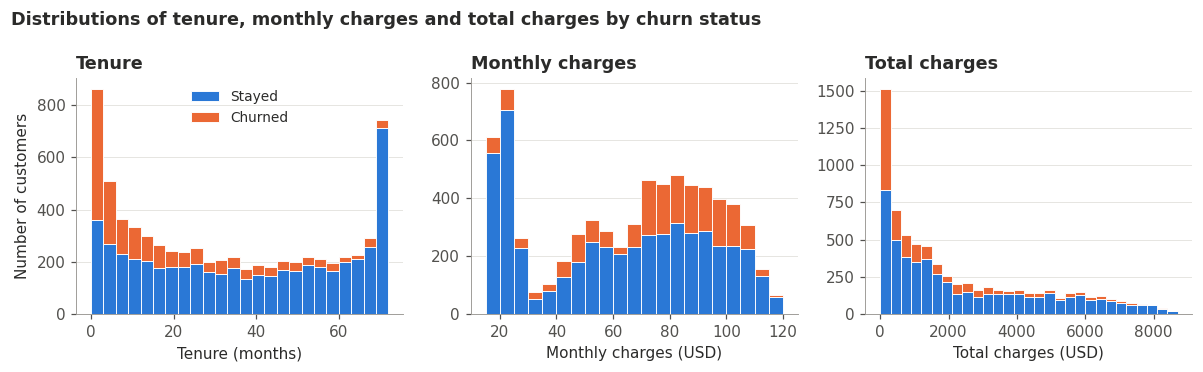

In [27]:
fig = ep.plot_numeric_distributions(eda)
ep.save_fig(fig, "fig04_numeric_distributions_by_churn.png")
plt.show()

**Figure 4 – interpretation**

Each bar shows customers who stayed (blue) stacked under those who churned (orange).
- **Tenure** is U-shaped, with many very new customers and many who have stayed about 72 months. Churners (orange) are concentrated in the first few months. Among customers who have stayed 5–6 years, churn is rare.
- **Monthly charges** have a large peak around 20 USD (mostly customers without internet, who rarely churn). There is a second broad group between 70 and 110 USD, where much of the churn occurs.
- **Total charges** are strongly right-skewed. Churners are concentrated at low totals, which is consistent with short tenure.
- **Relevance:** tenure and monthly charges look like useful predictors. Total charges largely repeats the tenure information, which is checked formally in the statistical analysis section.

### 4.4 Churn rate by contract, internet service, payment method and tenure group

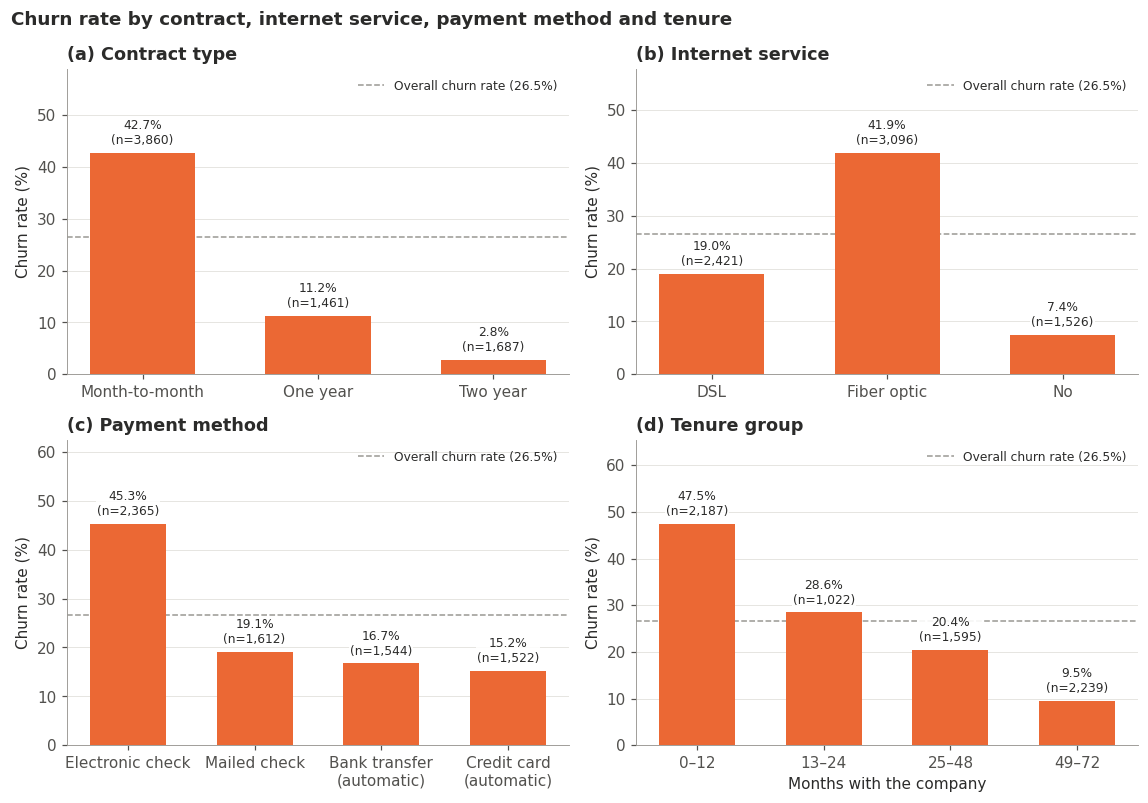

In [28]:
fig = ep.plot_key_segments(eda)
ep.save_fig(fig, "fig05_churn_rate_key_segments.png")
plt.show()

**Figure 5 – interpretation** (dashed line = overall churn rate of 26.5%)

| Panel | Finding | Relevance |
|---|---|---|
| (a) Contract | **Month-to-month 42.7%** vs one year 11.2% vs two year 2.8% | Clearest difference in the data. Short commitments are associated with much higher churn. |
| (b) Internet service | **Fiber optic 41.9%** vs DSL 19.0% vs no internet 7.4% | Fiber customers churn at more than twice the DSL rate. A possible link with fiber's higher price or service quality is a hypothesis this data cannot test. |
| (c) Payment method | **Electronic check 45.3%**; the other methods are 15–19% | Customers on automatic payments (bank transfer, credit card) churn least |
| (d) Tenure group | **47.5% in the first year**, falling to 9.5% after 4 years | Churn is concentrated early in the customer relationship |

Missing `Contract` values (35 customers) are excluded from panel (a).

### 4.5 Monthly charges versus churn

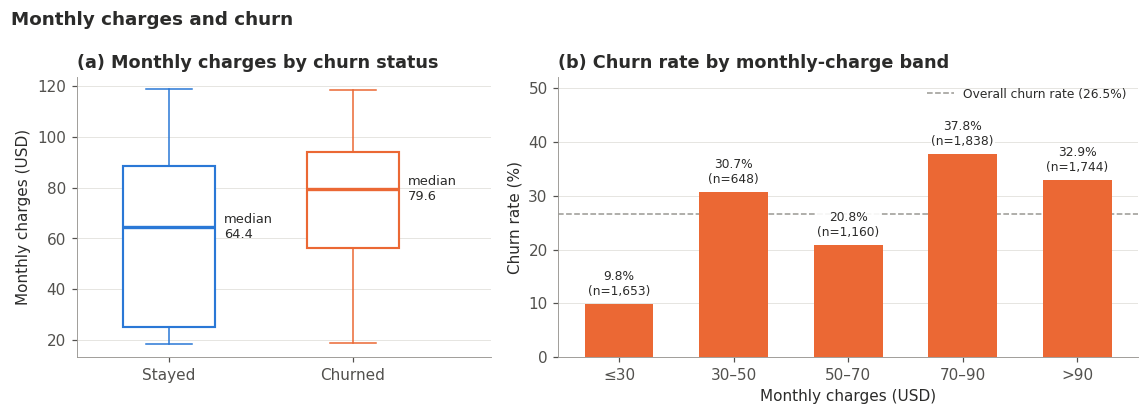

,customers,churned,churn_rate,share_of_customers,% DSL,% Fiber optic,% No
charge_band,,,,,,,
≤30,1653,162,9.8,23.5,7.7,0.0,92.3
30–50,648,199,30.7,9.2,100.0,0.0,0.0
50–70,1160,241,20.8,16.5,90.3,9.7,0.0
70–90,1838,694,37.8,26.1,30.0,70.0,0.0
>90,1744,573,32.9,24.8,2.7,97.3,0.0


In [29]:
fig, charge_bands = ep.plot_monthly_charges_vs_churn(eda)
ep.save_fig(fig, "fig06_monthly_charges_vs_churn.png")
plt.show()

service_mix = pd.crosstab(pd.cut(eda["MonthlyCharges"], bins=[0, 30, 50, 70, 90, 120],
                                 labels=["≤30", "30–50", "50–70", "70–90", ">90"]),
                          eda["InternetService"], normalize="index") * 100
charge_bands.join(service_mix.add_prefix("% ")).to_csv(config.TABLE_DIR / "t12_churn_by_monthly_charge_band.csv")
charge_bands.join(service_mix.add_prefix("% ")).round(1)

**Figure 6 – interpretation**
- **(a)** Churners pay more per month: median **79.6 USD** vs **64.4 USD** for customers who stayed.
- **(b)** The relationship is **not a simple "higher price → more churn"** pattern:

| Monthly charge | Churn rate | Main customer type in this band |
|---|---|---|
| ≤30 USD | 9.8% | 92% have no internet service |
| 30–50 USD | 30.7% | all DSL |
| 50–70 USD | 20.8% | 90% DSL |
| 70–90 USD | 37.8% | 70% fiber optic |
| >90 USD | 32.9% | 97% fiber optic |

- **Relevance:** the charge bands largely reflect **which service the customer has**. Monthly charges and internet type therefore overlap. Any "price effect" must be read together with service type, and a nonlinear model may capture this pattern better than a straight-line relationship.

### 4.6 Correlation heatmap (all variables)
**Making the categorical variables numeric.** A correlation needs numbers, so every categorical variable is converted to 0/1 columns, the same **one-hot encoding** the models use:
- **Yes/No variables** become one column (1 = Yes), e.g. `Partner`. Gender becomes `Male` (1 = male).
- "No internet service" and "No phone service" count as "No", exactly as in the model data. Otherwise the six add-on columns would be identical copies of `Internet: None`.
- **Multi-level variables** (InternetService, Contract, PaymentMethod) get **one column per level**, e.g. `Contract: Two year`. We never use label codes such as 0/1/2/3: they would invent a false order between the categories.

**Is a correlation with a 0/1 column valid?** Yes. Between two 0/1 columns it equals the *phi coefficient*; between a 0/1 column and a numeric one it is a (rank) point-biserial correlation. Both are standard measures.

**Why Spearman?** Tenure and total charges are skewed, and churn is a 0/1 variable. Spearman's rank correlation does not assume normal distributions or straight-line relationships, only that both variables tend to increase together (or in opposite directions). Correlations with churn are descriptive; the formal tests (chi-square with Cramér's V, Mann-Whitney) are in the statistical analysis section.

28 variables after encoding


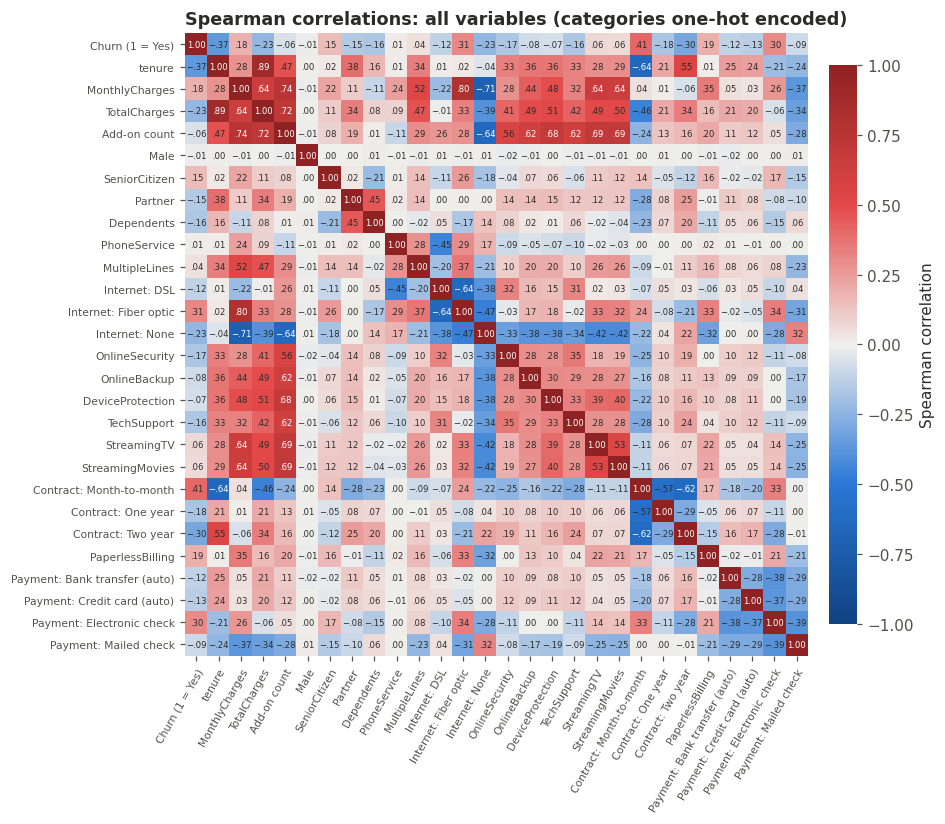

,rho_with_churn
Contract: Month-to-month,0.406
tenure,-0.367
Internet: Fiber optic,0.308
Contract: Two year,-0.302
Payment: Electronic check,0.302
TotalCharges,-0.230
Internet: None,-0.228
PaperlessBilling,0.192
MonthlyCharges,0.185
Contract: One year,-0.179


In [30]:
corr_data = ep.encode_for_correlation(eda)
spearman_all = corr_data.corr(method="spearman")          # pairwise-complete: the few missing categories are skipped
spearman_all.to_csv(config.TABLE_DIR / "t48_spearman_all_variables.csv")

# The numeric part (used in the text and the relationship plots) is also kept as its own table
numeric_part = ["tenure", "MonthlyCharges", "TotalCharges", "Add-on count", "Churn (1 = Yes)"]
spearman = spearman_all.loc[numeric_part, numeric_part]
spearman.to_csv(config.TABLE_DIR / "t13_spearman_correlations.csv")
print(f"{corr_data.shape[1]} variables after encoding")

fig = ep.plot_correlation_heatmap(spearman_all, "Spearman correlations: all variables (categories one-hot encoded)")
ep.save_fig(fig, "fig07_correlation_heatmap.png")
plt.show()

# Correlation of every variable with churn, strongest first
spearman_all["Churn (1 = Yes)"].drop("Churn (1 = Yes)").sort_values(key=abs, ascending=False).round(3).to_frame("rho_with_churn")

**Figure 7 – interpretation**

**Correlations with churn (first row/column)**
- **Strongest positive:** month-to-month contract **+0.41**, fiber optic internet **+0.31**, electronic check payment **+0.30**. These customers churn more.
- **Strongest negative:** tenure **−0.37**, two-year contract **−0.30**, no internet service **−0.23**, TotalCharges **−0.23**, OnlineSecurity **−0.17** and TechSupport **−0.16**. These customers churn less.
- **Near zero:** gender (Male −0.01) and PhoneService (+0.01): they are practically unrelated to churn, matching the chi-square results.
- MonthlyCharges is **+0.18**: customers with higher bills churn somewhat more.

**Correlations between predictors (multicollinearity warning signs)**
- **tenure ↔ TotalCharges = 0.89**, as expected from TotalCharges ≈ tenure × MonthlyCharges.
- **MonthlyCharges ↔ Fiber optic = 0.80** and **MonthlyCharges ↔ No internet = −0.71**: the bill is mostly determined by the services. This is why MonthlyCharges has a huge VIF and is excluded from the logistic regression (see the VIF analysis).
- **tenure ↔ Month-to-month = −0.64** and **tenure ↔ Two year = 0.55**: contract and tenure carry overlapping information.
- **Levels of the same variable are negatively correlated by construction** (e.g. Month-to-month ↔ Two year = −0.62), because a customer can only be in one level. This is not a finding.

**Add-on count vs churn is only −0.06 overall, yet Figure 9 shows a strong decline among internet customers.** Customers *without* internet have 0 add-ons but very low churn (7.4%), which cancels out the pattern. The individual add-ons show this too: protective services (OnlineSecurity, TechSupport) are negative, while streaming services are slightly positive. **One overall correlation can hide strong patterns within subgroups.**

#### Relationship plots: the scatter-plot equivalent for a yes/no target
The previous-year report used scatter plots with a trend line.

**Why a plain scatter plot doesn't work here:** our target is **binary** (churn = 0 or 1). A raw scatter plot would show only two horizontal lines of dots.

**What we plot instead:** the classification equivalent of a scatter plot with a trend line.
- **Each point** is a group of customers: one tenure month, or a 5-USD / 300-USD charge band.
- **Its height** is the group's **churn rate**.
- **Its size** is the number of customers in the group.
- **The navy line** is a LOWESS trend: a smooth line that, unlike a straight regression line, can bend if the relationship is not linear.
- **Each panel title** gives the Spearman correlation with churn (from Figure 7).
- Groups with fewer than 10 customers are not drawn, because their rates are too noisy.

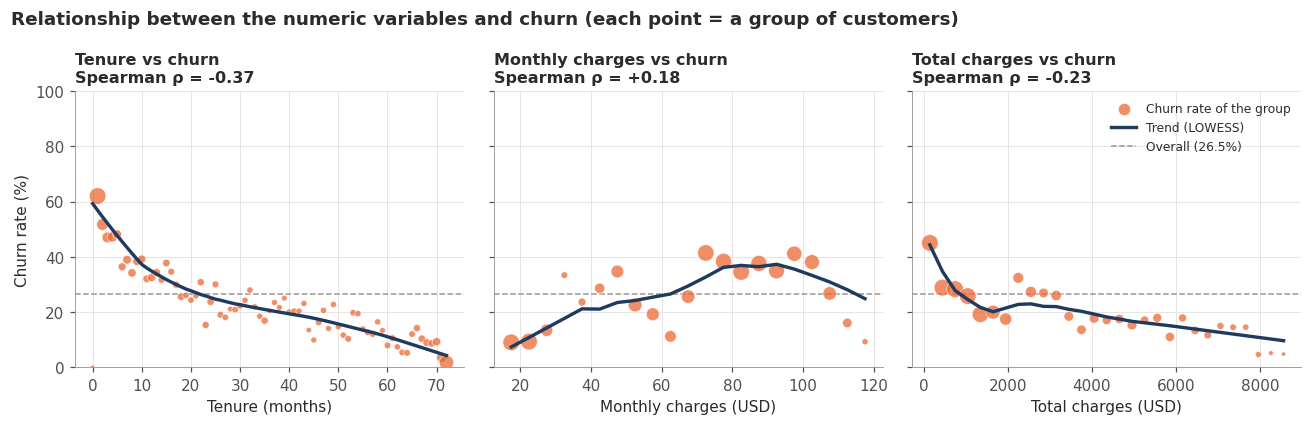

In [31]:
scatter_rates = ep.churn_rate_by_value(eda)
scatter_rates.to_csv(config.TABLE_DIR / "t46_churn_rate_by_value.csv", index=False)
spearman_with_churn = spearman["Churn (1 = Yes)"]
fig = ep.plot_churn_rate_scatter(scatter_rates, spearman_with_churn, overall_churn)
ep.save_fig(fig, "fig21_churn_rate_scatter_trend.png")
plt.show()

**Figure 21 – interpretation**
- **Tenure (ρ = −0.37):** the clearest relationship.
  - Churn is about 60% in the first month and falls steeply during the first year.
  - It then keeps declining steadily to almost zero for customers of about 6 years.
- **Monthly charges (ρ = +0.18):** **not a straight line.**
  - Churn rises from about 10% for the cheapest plans (mostly no internet) to about 35–40% at 70–100 USD (mostly fiber optic), then eases slightly for the most expensive plans.
  - The weak correlation hides this curved pattern. A tree-based model can capture it more easily than a straight-line model.
- **Total charges (ρ = −0.23):** high churn at low totals, which reflects new customers, then a gradual decline. This largely mirrors tenure.
- **Caution:** as with every EDA chart, these are associations, not causes.

### 4.7 Contract type and tenure together
Month-to-month customers are also usually newer. Is the contract pattern just a tenure effect?

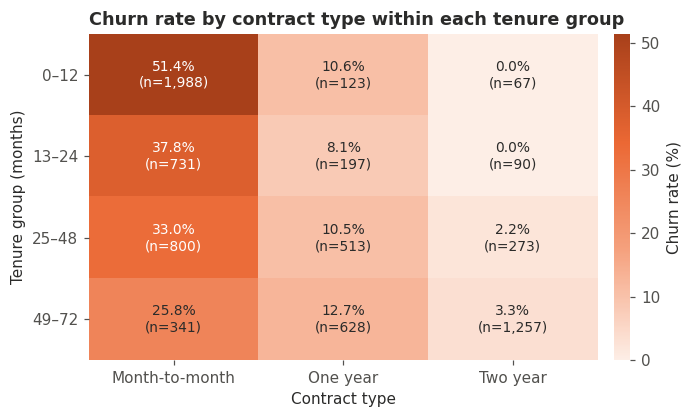

In [32]:
fig, ct_rate, ct_size = ep.plot_contract_tenure_heatmap(eda)
ep.save_fig(fig, "fig08_churn_contract_by_tenure.png")
plt.show()
pd.concat({"churn_rate_%": ct_rate, "customers": ct_size}, axis=1).to_csv(
    config.TABLE_DIR / "t14_churn_contract_by_tenure.csv")

**Figure 8 – interpretation**
- **Within month-to-month contracts**, churn falls with tenure, from 51.4% in the first year to 25.8% after four years.
- At **every** tenure level, month-to-month churn remains far above two-year contracts (at most 3.3%). One-year contracts sit between the two (8–13%).
- **So contract type and tenure each carry information about churn.** The contract pattern is not explained by tenure alone.
- **Caution:** some cells are small, e.g. only 67 two-year customers in their first year.

### 4.8 Service combinations: add-on services

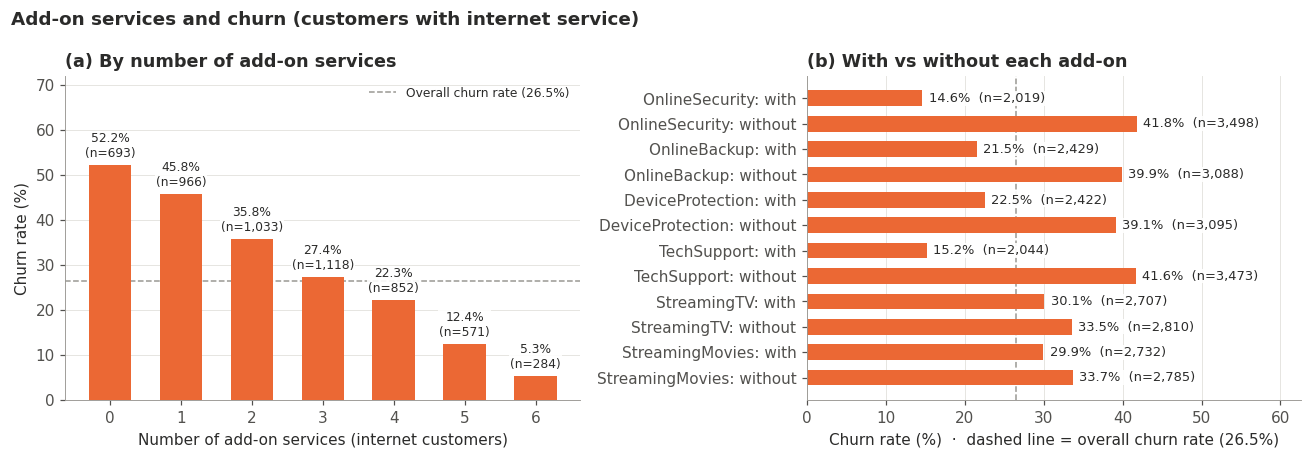

In [33]:
fig, addon_count_table, addon_table = ep.plot_services_panel(eda)
ep.save_fig(fig, "fig09_addon_services_churn.png")
plt.show()

**Figure 9 – interpretation** (internet customers only, since only they can buy add-ons)
- **(a)** Churn falls steadily with the number of add-ons: from **52.2% with none to 5.3% with all six**.
- **(b)** Add-ons fall into two groups:

| Add-on type | With the add-on | Without it |
|---|---|---|
| Online security | 14.6% | 41.8% |
| Tech support | 15.2% | 41.6% |
| Online backup / device protection | 21.5–22.5% | about 39% |
| Streaming TV / movies | about 30% | about 34% |

  - **Protective and support add-ons** show large differences.
  - **Streaming add-ons** make little difference.
- **Caution (confounding):** customers who have stayed longer have had more time to add services (correlation 0.47 between add-on count and tenure). Part of this pattern may reflect tenure rather than the add-ons themselves.

### 4.9 Demographic and billing attributes

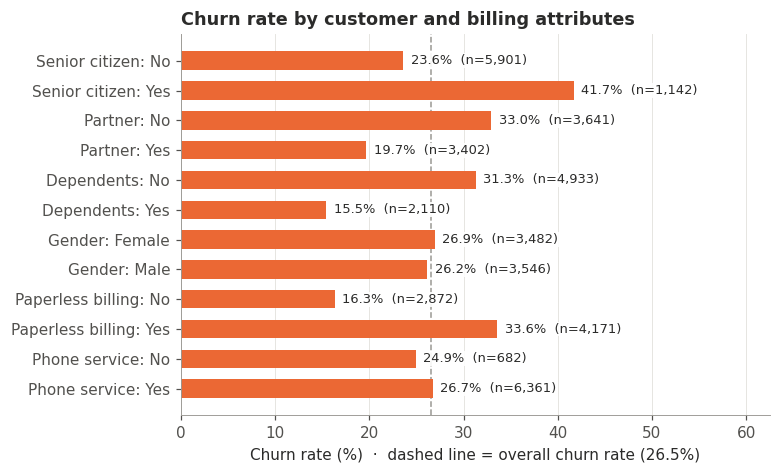

In [34]:
fig, attribute_table = ep.plot_customer_attributes(eda)
ep.save_fig(fig, "fig10_customer_attributes_churn.png")
plt.show()

**Figure 10 – interpretation**
- **Higher churn:**
  - senior citizens: **41.7%** vs 23.6%
  - customers **without** a partner: 33.0% vs 19.7%
  - customers **without** dependents: 31.3% vs 15.5%
  - customers with **paperless billing**: 33.6% vs 16.3%
- **Almost no difference:**
  - **gender**: 26.9% vs 26.2%
  - phone service: 24.9% vs 26.7%
- The gender result matters for fairness. Gender appears unrelated to churn here, and it would be inappropriate to use it to target customers.

### 4.10 Summary tables: churn rate by every category and customer profile

In [35]:
category_rates = ep.all_churn_rates(eda, config.CATEGORICAL_FEATURES + ["tenure_group"])
category_rates.to_csv(config.TABLE_DIR / "t15_churn_rate_by_category.csv", index=False)
category_rates.sort_values("churn_rate", ascending=False).head(12).round(1)

,variable,level,customers,churned,churn_rate,share_of_customers
43,tenure_group,0–12,2187,1038,47.5,31.1
41,PaymentMethod,Electronic check,2365,1071,45.3,33.6
34,Contract,Month-to-month,3860,1649,42.7,55.1
14,InternetService,Fiber optic,3096,1297,41.9,44.0
16,OnlineSecurity,No,3498,1461,41.8,49.7
3,SeniorCitizen,Yes,1142,476,41.7,16.2
25,TechSupport,No,3473,1446,41.6,49.3
19,OnlineBackup,No,3088,1233,39.9,43.8
22,DeviceProtection,No,3095,1211,39.1,43.9
31,StreamingMovies,No,2785,938,33.7,39.5


In [36]:
profile = ep.customer_profile_table(eda)
profile.to_csv(config.TABLE_DIR / "t16_customer_profile.csv")
profile.round(1)

,All customers,Stayed,Churned
Customers,7043.0,5174.0,1869.0
Share of all customers (%),100.0,73.5,26.5
Median tenure (months),29.0,38.0,10.0
Mean monthly charge (USD),64.8,61.3,74.4
Median total charges (USD),1394.4,1679.5,703.6
Month-to-month contract (%),55.1,42.9,88.7
Fiber optic internet (%),44.0,34.8,69.4
Pays by electronic check (%),33.6,25.0,57.3
Paperless billing (%),59.2,53.6,74.9
Senior citizen (%),16.2,12.9,25.5


**Customer profile – interpretation:** compared with customers who stayed, churners are much more likely to:

| Characteristic | Churned | Stayed |
|---|---|---|
| Month-to-month contract | 88.7% | 42.9% |
| Fiber optic internet | 69.4% | 34.8% |
| Pay by electronic check | 57.3% | 25.0% |
| Have tech support | 16.6% | 33.5% |
| Median tenure | 10 months | 38 months |

### 4.11 EDA summary: hypotheses for the statistical and modelling sections
| # | Pattern observed (association) | To be checked in |
|---|---|---|
| H1 | Month-to-month contracts are associated with much higher churn, at every tenure level | Chi-square test; model importance |
| H2 | Shorter tenure is associated with higher churn | Mann-Whitney U; model importance |
| H3 | Fiber optic and electronic-check customers churn more | Chi-square test |
| H4 | Protective/support add-ons (security, tech support) are associated with lower churn; streaming is not | Chi-square test |
| H5 | Higher monthly charges are associated with churn, but the pattern is non-linear and tied to service type | Mann-Whitney U; model comparison |
| H6 | Gender shows no meaningful association with churn | Chi-square test |
| H7 | TotalCharges is largely redundant given tenure and MonthlyCharges | VIF |

## 5. Statistical analysis
**What:** formally test the EDA hypotheses (H1–H7) and check for multicollinearity before modelling.

| Question | Test | Effect size (how big?) |
|---|---|---|
| Is a categorical variable associated with churn? | Chi-square test of independence | Cramér's V |
| Do churners and non-churners differ on a numeric variable? | Mann-Whitney U test | Rank-biserial correlation |
| Do numeric variables move together? | Spearman correlation | ρ (rho) |
| Are predictors redundant with each other? | Variance Inflation Factor (VIF) | VIF value |

**Statistical vs practical significance**
- A *p-value* only tells us whether a difference is unlikely to be pure chance.
- With 7,043 customers, even tiny differences produce p < 0.05. So we judge **practical importance with effect sizes**, using Cohen's (1988) guide: 0.10 = small, 0.30 = medium, 0.50 = large.

**Multiple testing**
- We run 19 tests: 16 chi-square and 3 Mann-Whitney.
- Testing many hypotheses increases the chance of at least one false "significant" result. The **Bonferroni correction** compensates by multiplying each p-value by 19, which is equivalent to requiring p < 0.05 / 19 ≈ 0.0026.

In [37]:
from src import stats_tests as st

N_TESTS = len(config.CATEGORICAL_FEATURES) + len(config.NUMERIC_FEATURES)
ALPHA = 0.05
print(f"Family of tests: {N_TESTS} | Bonferroni threshold: p < {ALPHA / N_TESTS:.4f}")

def format_p(p):
    # Very small p-values are shown as '< 0.001' (exact values are meaningless at that scale)
    return "< 0.001" if p < 0.001 else f"{p:.3f}"

Family of tests: 19 | Bonferroni threshold: p < 0.0026


### 5.1 Chi-square tests of independence (categorical variables vs churn)
**Hypotheses (for each variable):**
- **H0:** the variable and churn are independent, i.e. the churn rate is the same in every category.
- **H1:** the variable and churn are associated.

**Assumptions:**
1. Each observation is independent. This holds because there is one row per customer after duplicates were removed.
2. The expected count in every cell is at least 5. This is checked below.

Missing `gender` and `Contract` values are excluded from their own test.

In [38]:
chi_results = st.chi_square_table(clean, config.CATEGORICAL_FEATURES, n_tests=N_TESTS)
chi_results.to_csv(config.TABLE_DIR / "t17_chi_square_tests.csv", index=False)

print(f"Smallest expected cell count across all tables: {chi_results['min_expected_count'].min():.0f} "
      f"(assumption of >= 5 satisfied: {chi_results['min_expected_count'].min() >= 5})")
display_cols = ["variable", "n", "chi2", "dof", "p_value", "p_bonferroni", "cramers_v", "effect_size", "highest_churn_level"]
chi_results[display_cols].assign(p_value=chi_results["p_value"].map(format_p),
                                 p_bonferroni=chi_results["p_bonferroni"].map(format_p)).round(3)

Smallest expected cell count across all tables: 181 (assumption of >= 5 satisfied: True)


,variable,n,chi2,dof,p_value,p_bonferroni,cramers_v,effect_size,highest_churn_level
0,Contract,7008,1181.440,2,< 0.001,< 0.001,0.411,medium,Month-to-month (42.7%)
1,OnlineSecurity,7043,849.999,2,< 0.001,< 0.001,0.347,medium,No (41.8%)
2,TechSupport,7043,828.197,2,< 0.001,< 0.001,0.343,medium,No (41.6%)
3,InternetService,7043,732.310,2,< 0.001,< 0.001,0.322,medium,Fiber optic (41.9%)
4,PaymentMethod,7043,648.142,3,< 0.001,< 0.001,0.303,medium,Electronic check (45.3%)
5,OnlineBackup,7043,601.813,2,< 0.001,< 0.001,0.292,small,No (39.9%)
6,DeviceProtection,7043,558.419,2,< 0.001,< 0.001,0.282,small,No (39.1%)
7,StreamingMovies,7043,375.661,2,< 0.001,< 0.001,0.231,small,No (33.7%)
8,StreamingTV,7043,374.204,2,< 0.001,< 0.001,0.231,small,No (33.5%)
9,PaperlessBilling,7043,259.161,1,< 0.001,< 0.001,0.192,small,Yes (33.6%)


**Interpretation**
- **13 of 16** categorical variables are significantly associated with churn after the Bonferroni correction.
- **Not significant:** `gender` (p ≈ 0.47), `PhoneService` (p ≈ 0.32) and `MultipleLines` (adjusted p ≈ 0.07). Their effect sizes are essentially zero (V ≤ 0.04).
- **Largest effect sizes:**
  - `Contract` (V = 0.41, medium)
  - `OnlineSecurity` and `TechSupport` (0.35 and 0.34)
  - `InternetService` (0.32)
  - `PaymentMethod` (0.30)
- **Demographics:** Senior, Partner and Dependents are significant, but their effects are *small* (V ≈ 0.15–0.16).

### 5.2 Add-on services: a fairer test among internet customers only
Each add-on column includes the level "No internet service", which duplicates `InternetService = No`. Part of the association above therefore just reflects having internet at all. We re-test **Yes vs No among internet customers only**.

In [39]:
internet_customers = clean[clean["InternetService"] != "No"]
addon_tests = st.chi_square_table(internet_customers, config.ADDON_SERVICES, n_tests=len(config.ADDON_SERVICES))
addon_tests.to_csv(config.TABLE_DIR / "t18_chi_square_addons_internet_only.csv", index=False)
addon_tests[["variable", "n", "chi2", "p_value", "cramers_v", "effect_size",
             "lowest_churn_level", "highest_churn_level"]].assign(
    p_value=addon_tests["p_value"].map(format_p)).round(3)

,variable,n,chi2,p_value,cramers_v,effect_size,lowest_churn_level,highest_churn_level
0,OnlineSecurity,5517,435.059,< 0.001,0.281,small,Yes (14.6%),No (41.8%)
1,TechSupport,5517,415.471,< 0.001,0.274,small,Yes (15.2%),No (41.6%)
2,OnlineBackup,5517,212.073,< 0.001,0.196,small,Yes (21.5%),No (39.9%)
3,DeviceProtection,5517,173.086,< 0.001,0.177,small,Yes (22.5%),No (39.1%)
4,StreamingMovies,5517,8.886,0.003,0.040,negligible,Yes (29.9%),No (33.7%)
5,StreamingTV,5517,7.576,0.006,0.037,negligible,Yes (30.1%),No (33.5%)


**Interpretation:** among internet customers the add-ons fall into two clear groups.

| Add-on | Cramér's V | Churn with / without |
|---|---|---|
| Online security | 0.28 | 14.6% vs 41.8% |
| Tech support | 0.27 | 15.2% vs 41.6% |
| Online backup / device protection | 0.18–0.20 | ~22% vs ~39% |
| Streaming TV / movies | about 0.04 (negligible) | |

- Streaming add-ons looked "small" (V = 0.23) in Section 5.1, but that apparent effect came almost entirely from the "No internet service" level.
- **This supports H4:** protective and support services, not entertainment services, are associated with lower churn.

### 5.3 Mann-Whitney U tests (numeric variables vs churn)
**Why not a t-test?**
- Tenure is U-shaped (many very new and many very long-standing customers).
- `TotalCharges` is right-skewed (skewness ≈ 0.96).
- Monthly charges are bimodal.
- The t-test compares means and assumes roughly normal data. Mann-Whitney U compares **ranks**, so it needs no normality assumption and is robust to skew.

**Hypotheses:**
- **H0:** churners and non-churners have the same distribution. A random churner is equally likely to have a higher or lower value than a random non-churner.
- **H1:** the distributions differ.

In [40]:
mw_results = st.mann_whitney_table(clean, config.NUMERIC_FEATURES, n_tests=N_TESTS)
mw_results.to_csv(config.TABLE_DIR / "t19_mann_whitney_tests.csv", index=False)
mw_results.assign(p_value=mw_results["p_value"].map(format_p),
                  p_bonferroni=mw_results["p_bonferroni"].map(format_p)).round(3).T

,0,1,2
variable,tenure,MonthlyCharges,TotalCharges
median_churned,10.0,79.6,703.55
median_stayed,38.0,64.425,1679.525
mean_churned,17.979,74.44,1531.814
mean_stayed,37.569,61.267,2549.98
skewness,0.24,-0.22,0.963
U,2515524.5,6002750.0,3381266.0
p_value,< 0.001,< 0.001,< 0.001
p_bonferroni,< 0.001,< 0.001,< 0.001
significant_after_bonferroni,True,True,True


**Interpretation**

All three differences are significant (p < 0.001, also after Bonferroni).

| Variable | Median: churners vs stayed | Chance a random churner has the higher value | Rank-biserial r | Effect |
|---|---|---|---|---|
| tenure | 10 vs 38 months | 26% | −0.48 | medium (the largest numeric effect) |
| TotalCharges | 704 vs 1,680 USD | 35% | −0.30 | medium |
| MonthlyCharges | 79.6 vs 64.4 USD | 62% | +0.24 | small |

- The negative tenure value means churners have shorter tenure. A churner has a higher tenure than a random non-churner only 26% of the time.
- TotalCharges' effect largely reflects tenure.
- Monthly charges show a **small** effect: higher-paying customers churn somewhat more, but much less strongly than the tenure difference.

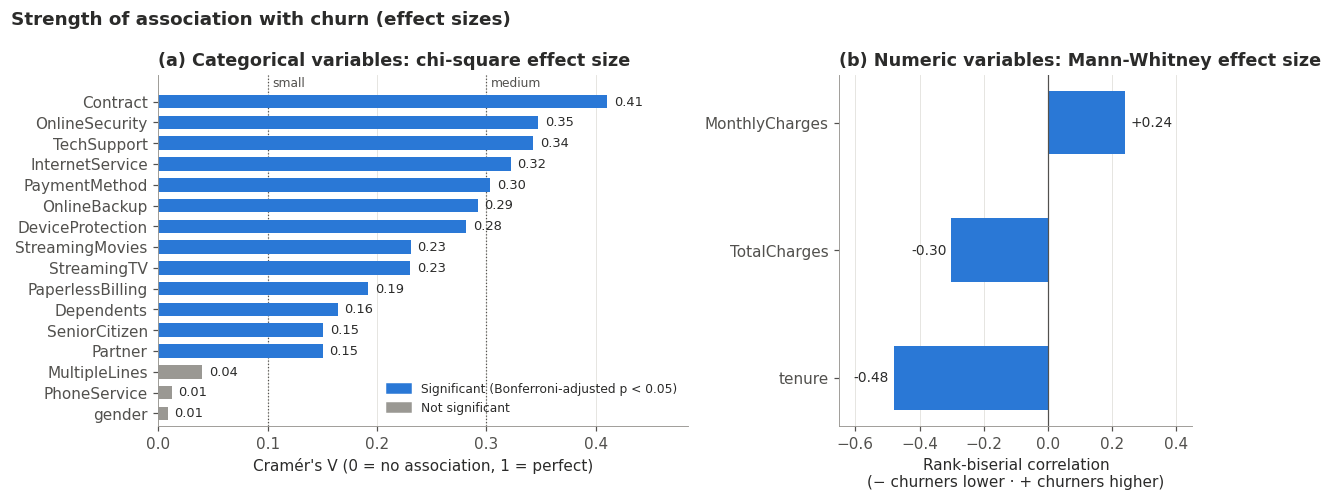

In [41]:
fig = ep.plot_effect_sizes(chi_results, mw_results)
ep.save_fig(fig, "fig11_effect_sizes.png")
plt.show()

**Figure 11 – interpretation:** this chart separates **practical importance** from significance. Every blue bar is statistically significant, but their sizes differ greatly.
- **Most strongly associated with churn:** contract type, tenure, online security, tech support, internet type and payment method.
- **Weak:** demographic variables.
- **Essentially unrelated:** gender, phone service and multiple lines.

### 5.4 Correlation analysis (numeric variables)
Spearman correlations with p-values, complementing the heatmap in Figure 7.

In [42]:
from itertools import combinations
from scipy.stats import spearmanr

spearman_rows = []
corr_vars = config.NUMERIC_FEATURES + ["churn_flag"]
for a, b in combinations(corr_vars, 2):
    rho, p = spearmanr(eda[a], eda[b])
    spearman_rows.append({"variable_1": a, "variable_2": b, "spearman_rho": rho,
                          "p_value": p, "strength": st.effect_size_label(rho)})
spearman_tests = pd.DataFrame(spearman_rows)
spearman_tests.to_csv(config.TABLE_DIR / "t20_spearman_tests.csv", index=False)
spearman_tests.assign(p_value=spearman_tests["p_value"].map(format_p)).round(3)

,variable_1,variable_2,spearman_rho,p_value,strength
0,tenure,MonthlyCharges,0.276,< 0.001,small
1,tenure,TotalCharges,0.890,< 0.001,large
2,tenure,churn_flag,-0.367,< 0.001,medium
3,MonthlyCharges,TotalCharges,0.638,< 0.001,large
4,MonthlyCharges,churn_flag,0.185,< 0.001,small
5,TotalCharges,churn_flag,-0.230,< 0.001,small


**Interpretation:** all correlations are significant at this sample size. The important information is their size:
- **tenure ↔ TotalCharges ρ = 0.89** is very strong, signalling redundancy.
- **MonthlyCharges ↔ TotalCharges ρ = 0.64.**
- Among the correlations with churn, tenure is strongest (ρ = −0.37).

### 5.5 Multicollinearity: Variance Inflation Factor (VIF)
**What:** VIF measures how well each predictor can be predicted from the *other* predictors, as VIF = 1 / (1 − R²).
- **VIF = 1:** the predictor is independent of the others.
- **VIF > 5:** worth noting.
- **VIF > 10:** serious.

**Why it matters:** when predictors are highly redundant, a **logistic regression's coefficients become unstable and hard to interpret**. The model cannot tell which of two near-duplicate variables deserves the credit. Prediction accuracy is usually less affected.

**Leakage note:** because the result informs a modelling decision, VIF is computed on the **training set only**.

#### (a) The three numeric variables

In [43]:
train_numeric = X_train[config.NUMERIC_FEATURES].fillna(X_train[config.NUMERIC_FEATURES].median())
vif_numeric = st.vif_table(train_numeric)
vif_numeric.to_csv(config.TABLE_DIR / "t21_vif_numeric.csv", index=False)
vif_numeric.round(2)

,feature,VIF,concern
0,TotalCharges,9.69,moderate (>5)
1,tenure,5.93,moderate (>5)
2,MonthlyCharges,3.23,low


#### (b) Does standardising the variables reduce VIF? No.
Some reports claim that scaling "reduces multicollinearity", including the previous-year example report. We test that claim directly.

In [44]:
train_scaled = (train_numeric - train_numeric.mean()) / train_numeric.std()
scaling_demo = pd.DataFrame({
    "VIF raw (with intercept)": st.vif_table(train_numeric).set_index("feature")["VIF"],
    "VIF standardised (with intercept)": st.vif_table(train_scaled).set_index("feature")["VIF"],
    "VIF raw (NO intercept - incorrect)": pd.Series(st.vif_without_intercept(train_numeric), index=train_numeric.columns),
    "VIF standardised (NO intercept)": pd.Series(st.vif_without_intercept(train_scaled), index=train_numeric.columns),
}).loc[config.NUMERIC_FEATURES]
scaling_demo.to_csv(config.TABLE_DIR / "t22_vif_scaling_demo.csv")
scaling_demo.round(2)

,VIF raw (with intercept),VIF standardised (with intercept),VIF raw (NO intercept - incorrect),VIF standardised (NO intercept)
tenure,5.93,5.93,6.47,5.93
MonthlyCharges,3.23,3.23,3.39,3.23
TotalCharges,9.69,9.69,8.21,9.69


**Interpretation**
- **When VIF is computed correctly** (with an intercept), standardising changes **nothing**: the first two columns are identical. VIF depends on correlations between predictors, and re-scaling a variable does not change its correlations.
- **If the intercept is omitted** (a common coding mistake with `statsmodels`), the raw and scaled versions give different numbers. This makes it *look* as if scaling changed multicollinearity, but that is an artefact of the incorrect calculation.

**Conclusion:** scaling does **not** resolve multicollinearity. The real remedies are:
- removing or combining redundant variables
- regularisation
- simply not interpreting the affected coefficients

#### (c) The full logistic-regression design matrix
In the model, each categorical variable becomes one-hot dummy columns. Here we use reference-level ("drop first") coding, as logistic regression will.

In [45]:
from sklearn.linear_model import LinearRegression

design_pre = md.build_preprocessor(onehot_drop="first", scale_numeric=False).fit(X_train)
design = pd.DataFrame(design_pre.transform(X_train), columns=design_pre.get_feature_names_out(), index=X_train.index)

vif_full = st.vif_table(design)
vif_full.to_csv(config.TABLE_DIR / "t23_vif_full_design.csv", index=False)

service_cols = [c for c in design.columns if c not in config.NUMERIC_FEATURES]
r2_monthly = LinearRegression().fit(design[service_cols], design["MonthlyCharges"]).score(
    design[service_cols], design["MonthlyCharges"])
print(f"R² of MonthlyCharges explained by the categorical/service columns alone: {r2_monthly:.4f}")
vif_full.head(10).round(1)

R² of MonthlyCharges explained by the categorical/service columns alone: 0.9988


,feature,VIF,concern
0,MonthlyCharges,836.1,serious (>10)
1,InternetService_Fiber optic,143.3,serious (>10)
2,InternetService_No,100.1,serious (>10)
3,PhoneService_Yes,34.3,serious (>10)
4,StreamingTV_Yes,23.4,serious (>10)
5,StreamingMovies_Yes,23.3,serious (>10)
6,TotalCharges,11.0,serious (>10)
7,tenure,7.6,moderate (>5)
8,MultipleLines_Yes,7.1,moderate (>5)
9,DeviceProtection_Yes,6.8,moderate (>5)


**Interpretation (important for modelling)**
- **`MonthlyCharges` has a VIF in the hundreds.**
  - The service dummies (internet type, phone, streaming, add-ons…) explain **99.9%** of its variance (R² ≈ 0.999). In other words, a customer's monthly bill is almost exactly the sum of the prices of the services they subscribe to.
  - The internet-type, phone and streaming dummies inherit high VIFs for the same reason.
- **`TotalCharges` (VIF ≈ 10)** is close to tenure × MonthlyCharges.

#### (d) Remedy for logistic regression: remove the two redundant charge variables

In [46]:
lr_features = [c for c in design.columns if c not in config.LR_EXCLUDED_FEATURES]
vif_reduced = st.vif_table(design[lr_features])
vif_reduced.to_csv(config.TABLE_DIR / "t24_vif_reduced_design.csv", index=False)
print(f"Columns removed for logistic regression: {config.LR_EXCLUDED_FEATURES}")
print(f"Largest VIF after removal: {vif_reduced['VIF'].max():.2f} ({vif_reduced.loc[0, 'feature']})")
vif_reduced.head(8).round(2)

Columns removed for logistic regression: ['MonthlyCharges', 'TotalCharges']
Largest VIF after removal: 2.78 (tenure)


,feature,VIF,concern
0,tenure,2.78,low
1,InternetService_No,2.71,low
2,Contract_Two year,2.60,low
3,InternetService_Fiber optic,2.02,low
4,PaymentMethod_Electronic check,1.97,low
5,PaymentMethod_Mailed check,1.84,low
6,StreamingMovies_Yes,1.65,low
7,StreamingTV_Yes,1.64,low


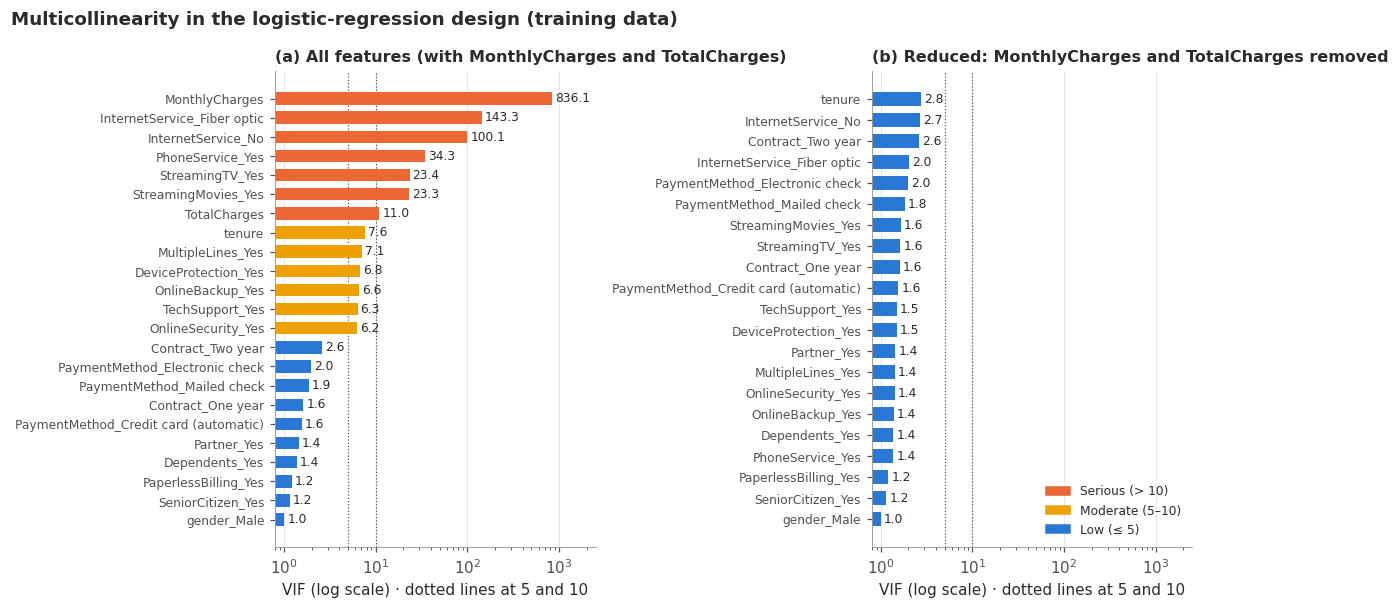

In [47]:
from src import model_plots as mp

fig = mp.plot_vif_comparison(vif_full, vif_reduced,
                              "(a) All features (with MonthlyCharges and TotalCharges)",
                              "(b) Reduced: MonthlyCharges and TotalCharges removed")
ep.save_fig(fig, "fig20_vif_before_after.png")
plt.show()

**Figure 20 – interpretation**
- **(a)** Several variables exceed the "serious" threshold of 10. `MonthlyCharges` is far beyond it because it is essentially the sum of the service prices.
- **(b)** After removing the two redundant charge columns, every VIF is low (below 3).
- **Contrast with the previous-year report:** their before/after charts compared VIF *before and after scaling*. As shown in Section 5.5(b), scaling cannot change VIF. The remedy that actually works is removing (or combining) redundant variables, which is what this figure shows.

**Decision**
- **Logistic regression** will use all features **except `MonthlyCharges` and `TotalCharges`**. After removing them, every VIF is below 3, so the coefficients (odds ratios) can be interpreted reliably.
- **Little information is lost:**
  - monthly charges are reconstructed almost perfectly by the service columns
  - total charges largely duplicates tenure and the service mix
- In the modelling section we will **verify with cross-validation** that this reduced model predicts as well as one using all features.
- **Decision tree and random forest keep all features.** Tree splits do not rely on coefficient estimates, so redundancy does not destabilise them in the same way. Their importance scores will still share credit between correlated features, and we will remember this when interpreting them.

### 5.6 Hypothesis summary

In [48]:
chi_v = chi_results.set_index("variable")["cramers_v"]
chi_p = chi_results.set_index("variable")["p_bonferroni"]
addon_v = addon_tests.set_index("variable")["cramers_v"]
mw = mw_results.set_index("variable")
vif_tc = vif_numeric.set_index("feature").loc["TotalCharges", "VIF"]
rho_tenure_tc = spearman_tests.query("variable_1 == 'tenure' and variable_2 == 'TotalCharges'")["spearman_rho"].iloc[0]

hypotheses = pd.DataFrame([
    ["H1", "Contract type is associated with churn",
     f"V = {chi_v['Contract']:.2f} (medium), p < 0.001", "Supported"],
    ["H2", "Shorter tenure is associated with churn",
     f"medians {mw.loc['tenure', 'median_churned']:.0f} vs {mw.loc['tenure', 'median_stayed']:.0f} months, "
     f"r = {mw.loc['tenure', 'rank_biserial']:.2f} (medium), p < 0.001", "Supported"],
    ["H3", "Fiber optic and electronic-check customers churn more",
     f"InternetService V = {chi_v['InternetService']:.2f}; PaymentMethod V = {chi_v['PaymentMethod']:.2f}; both p < 0.001",
     "Supported"],
    ["H4", "Protective/support add-ons are associated with lower churn; streaming is not",
     f"internet customers: OnlineSecurity V = {addon_v['OnlineSecurity']:.2f}, TechSupport V = {addon_v['TechSupport']:.2f}; "
     f"StreamingTV V = {addon_v['StreamingTV']:.2f}", "Supported"],
    ["H5", "Higher monthly charges are associated with churn",
     f"medians {mw.loc['MonthlyCharges', 'median_churned']:.1f} vs {mw.loc['MonthlyCharges', 'median_stayed']:.1f} USD, "
     f"r = {mw.loc['MonthlyCharges', 'rank_biserial']:.2f} (small); pattern is non-linear and tied to service type",
     "Partly supported (small effect)"],
    ["H6", "Gender shows no meaningful association",
     f"V = {chi_v['gender']:.2f}, adjusted p = {format_p(chi_p['gender'])}", "Supported (no association)"],
    ["H7", "TotalCharges is redundant given tenure and MonthlyCharges",
     f"VIF = {vif_tc:.1f}; Spearman rho with tenure = {rho_tenure_tc:.2f}",
     "Supported"],
], columns=["id", "hypothesis", "evidence", "conclusion"])
hypotheses.to_csv(config.TABLE_DIR / "t25_hypothesis_summary.csv", index=False)
pd.set_option("display.max_colwidth", 120)
hypotheses

,id,hypothesis,evidence,conclusion
0,H1,Contract type is associated with churn,"V = 0.41 (medium), p < 0.001",Supported
1,H2,Shorter tenure is associated with churn,"medians 10 vs 38 months, r = -0.48 (medium), p < 0.001",Supported
2,H3,Fiber optic and electronic-check customers churn more,InternetService V = 0.32; PaymentMethod V = 0.30; both p < 0.001,Supported
3,H4,Protective/support add-ons are associated with lower churn; streaming is not,"internet customers: OnlineSecurity V = 0.28, TechSupport V = 0.27; StreamingTV V = 0.04",Supported
4,H5,Higher monthly charges are associated with churn,"medians 79.6 vs 64.4 USD, r = 0.24 (small); pattern is non-linear and tied to service type",Partly supported (small effect)
5,H6,Gender shows no meaningful association,"V = 0.01, adjusted p = 1.000",Supported (no association)
6,H7,TotalCharges is redundant given tenure and MonthlyCharges,VIF = 9.7; Spearman rho with tenure = 0.89,Supported


### 5.7 Limitations of the statistical tests
1. **Association is not causation.** The tests show that variables and churn occur together, not that one causes the other. For example, contract type and tenure are themselves related (Figure 8).
2. **One variable at a time.** Each chi-square or Mann-Whitney test ignores the other variables, so overlapping effects can each look strong. The multivariable models in the next section examine variables jointly.
3. **Large sample.** With n ≈ 7,000, p-values are tiny for almost everything. That is why conclusions rest on the effect sizes.
4. **Bonferroni is conservative.** It reduces false positives but can miss weak real effects. This does not change any conclusion here: the borderline variable (MultipleLines) has a negligible effect size either way.
5. **Cohen's thresholds are conventions**, not laws. A "small" effect can still matter commercially if it affects many customers.
6. **Snapshot data.** All variables are measured at one point in time, so the order of events (e.g. whether a customer switched to month-to-month before deciding to leave) is unknown.

## 6. Machine learning: model development and evaluation
**Task:** binary classification. Predict whether a customer churns (1) or stays (0).

**Protocol (fixed in advance to keep the evaluation honest)**
1. **Tune** each model with a grid search and **stratified 5-fold cross-validation on the training set only**.
2. **Select** the final model with a pre-defined rule: highest mean CV ROC-AUC. If another model is within 0.01, choose the more interpretable one (Logistic Regression > Decision Tree > Random Forest).
3. **Evaluate** every model **once** on the untouched test set (1,409 customers) for a fair comparison.

**Metrics** (positive class = churn):

| Metric | Plain-English meaning |
|---|---|
| Accuracy | Share of all predictions that are correct. Misleading with imbalance. |
| Precision | Of the customers we flag as "will churn", how many really churn? |
| Recall | Of the customers who really churn, how many do we catch? |
| F1-score | Harmonic mean of precision and recall; a single balance measure |
| ROC-AUC | Probability that a random churner gets a higher risk score than a random non-churner (0.5 = guessing, 1 = perfect). Threshold-independent. |
| PR-AUC (average precision) | Precision–recall trade-off summarised over all thresholds; more informative than ROC-AUC when positives are the minority (Saito & Rehmsmeier, 2015). Baseline = churn rate (≈0.27). |

**Business meaning of errors**
- **False negative (FN):** a customer who will churn but is *not* flagged. The company loses the customer and their future revenue without trying to keep them.
- **False positive (FP):** a loyal customer who *is* flagged. The company spends a retention offer (e.g. a discount) on someone who would have stayed anyway.

Usually a lost customer costs more than a retention offer, so **recall is generally more valuable than precision** here. Too many false positives still waste budget, though.

**Why ROC-AUC for selection?** In practice the model would *rank* customers by risk so that the retention team can contact the riskiest first. ROC-AUC measures exactly this ranking ability. It also does not depend on any particular threshold, which can be set later to suit the budget.

**Class imbalance:** all models use `class_weight="balanced"`, decided in advance so that every model's default 0.5 threshold is comparable. Section 6.2 shows what weighting changes.

In [49]:
import warnings
import joblib
import json
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, cross_validate, cross_val_predict
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from src import model_plots as mp

cv = md.make_cv()
print(f"Training set: {len(X_train):,} customers | test set: {len(X_test):,} customers")
print(f"Cross-validation: {cv}")

Training set: 5,634 customers | test set: 1,409 customers
Cross-validation: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


### 6.1 Baseline: a model that always predicts "No churn"
Any useful model must clearly beat this `DummyClassifier`.

In [50]:
dummy = DummyClassifier(strategy="most_frequent")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")   # precision is undefined when nothing is predicted as churn
    dummy_cv = cross_validate(dummy, X_train, y_train, cv=cv, scoring=md.CV_SCORING)
dummy_cv_summary = {"model": "Dummy (always 'No churn')"}
for metric in md.CV_SCORING:
    dummy_cv_summary[f"cv_{metric}_mean"] = dummy_cv[f"test_{metric}"].mean()
    dummy_cv_summary[f"cv_{metric}_sd"] = dummy_cv[f"test_{metric}"].std()
pd.Series(dummy_cv_summary).drop("model").astype(float).round(3).to_frame("Dummy – CV on training set").T

,cv_roc_auc_mean,cv_roc_auc_sd,cv_pr_auc_mean,cv_pr_auc_sd,cv_accuracy_mean,cv_accuracy_sd,cv_precision_mean,cv_precision_sd,cv_recall_mean,cv_recall_sd,cv_f1_mean,cv_f1_sd
Dummy – CV on training set,0.5,0.0,0.265,0.0,0.735,0.0,0.0,0.0,0.0,0.0,0.0,0.0


**Interpretation:** the baseline reaches **73.5% accuracy** while catching **zero churners**: recall, precision and F1 are all 0, and ROC-AUC is 0.50, no better than guessing. This is the clearest demonstration of why accuracy alone is misleading here. Every real model must beat **ROC-AUC 0.50 and PR-AUC 0.265**, the share of churners.

### 6.2 Two design checks (cross-validation on the training set only)
**(a) What does class weighting change?** We compare logistic regression with and without `class_weight="balanced"`.

In [51]:
lr_num, lr_cat = md.lr_feature_lists(include_charges=False)
weight_rows = []
for weight in [None, "balanced"]:
    pipe = md.make_pipeline(LogisticRegression(max_iter=5000, class_weight=weight), lr_num, lr_cat,
                            onehot_drop="first")
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=md.CV_SCORING)
    weight_rows.append({"class_weight": str(weight),
                        **{m: res[f"test_{m}"].mean() for m in md.CV_SCORING}})
class_weight_check = pd.DataFrame(weight_rows).set_index("class_weight")
class_weight_check.to_csv(config.TABLE_DIR / "t26_class_weight_check.csv")
class_weight_check.round(3)

,roc_auc,pr_auc,accuracy,precision,recall,f1
class_weight,,,,,,
None,0.845,0.660,0.801,0.652,0.536,0.588
balanced,0.845,0.659,0.752,0.521,0.794,0.629


**Interpretation:** class weighting **does not change the model's ability to rank customers** (ROC-AUC 0.845 in both cases, PR-AUC about 0.66). What it changes is where the default 0.5 threshold falls on the precision–recall trade-off:

| | Recall | Precision | F1 | Accuracy |
|---|---|---|---|---|
| Unweighted | 53.6% | 65.2% | 0.588 | 80.1% |
| Balanced | **79.4%** | 52.1% | **0.629** | 75.2% |

- The balanced model catches far more churners.
- Accuracy falls, but the dummy example already showed that accuracy is the wrong target.
- Because missing a churner is usually costlier than an unnecessary offer, `class_weight="balanced"` is the better default for this business problem. Using it for all models keeps their 0.5 thresholds comparable.

**(b) Does dropping MonthlyCharges and TotalCharges hurt logistic regression?** (They were removed because of multicollinearity in Section 5.5.)

In [52]:
feature_rows = []
for label, include in [("Reduced (no MonthlyCharges / TotalCharges)", False), ("All features", True)]:
    num, cat = md.lr_feature_lists(include_charges=include)
    pipe = md.make_pipeline(LogisticRegression(max_iter=5000, class_weight="balanced"), num, cat,
                            onehot_drop="first")
    search = GridSearchCV(pipe, {"model__C": [0.01, 0.1, 1, 10]}, scoring="roc_auc", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    i = search.best_index_
    feature_rows.append({"feature_set": label, "n_input_columns": len(num) + len(cat),
                         "best_C": search.best_params_["model__C"],
                         "cv_roc_auc_mean": search.cv_results_["mean_test_score"][i],
                         "cv_roc_auc_sd": search.cv_results_["std_test_score"][i]})
lr_feature_check = pd.DataFrame(feature_rows).set_index("feature_set")
lr_feature_check.to_csv(config.TABLE_DIR / "t27_lr_feature_set_check.csv")
lr_feature_check.round(4)

,n_input_columns,best_C,cv_roc_auc_mean,cv_roc_auc_sd
feature_set,,,,
Reduced (no MonthlyCharges / TotalCharges),17,1,0.8448,0.0123
All features,19,10,0.8462,0.0129


**Interpretation:** removing `MonthlyCharges` and `TotalCharges` lowers the CV ROC-AUC by only **0.0014** (0.8448 vs 0.8462). That is about one-tenth of the fold-to-fold standard deviation (≈0.012), so it is negligible. The reduced model keeps the same predictive power while giving stable, interpretable coefficients. This confirms the VIF-based decision.

### 6.3 Hyperparameter tuning with grid search and cross-validation
**What:** for each model, try every combination in a small grid of settings (hyperparameters). Each combination is scored by 5-fold cross-validation **on the training set**.

**How cross-validation works:**
- The training set is split into 5 folds. Each fold takes one turn as the validation set while the model trains on the other four.
- The 5 scores are averaged. This gives a more reliable estimate than a single split and never touches the test set.
- Because preprocessing is inside the Pipeline, the imputer, scaler and encoder are **re-fitted on each training fold** (no leakage).

| Model | Hyperparameters tuned | What they control |
|---|---|---|
| Logistic Regression | `C` = 0.01, 0.1, 1, 10 | Regularisation strength. Smaller C means stronger shrinkage of coefficients, which reduces overfitting. |
| Decision Tree | `max_depth` = 3–8, `min_samples_leaf` = 1–50 | How deep the tree may grow and how small its final groups may be. Both limit overfitting. |
| Random Forest | `max_depth`, `min_samples_leaf`, `max_features` (sqrt or 50% of columns) | Size of each tree and how many features each split may consider. 300 trees are used. |

In [53]:
searches, cv_rows = {}, []
for name, (pipeline, grid) in md.get_model_specs().items():
    search = md.tune_model(pipeline, grid, X_train, y_train)
    searches[name] = search
    cv_rows.append(md.cv_summary(search, name))
    print(f"{name:20s} best params: {cv_rows[-1]['best_params']}  CV ROC-AUC = {search.best_score_:.4f}")

cv_table = pd.DataFrame([dummy_cv_summary] + cv_rows).set_index("model")
cv_table.to_csv(config.TABLE_DIR / "t28_cv_results.csv")
cv_display = pd.DataFrame({
    label: cv_table[f"cv_{key}_mean"].map("{:.3f}".format) + " ± " + cv_table[f"cv_{key}_sd"].map("{:.3f}".format)
    for key, label in mp.METRIC_LABELS.items()})
cv_display

Logistic Regression  best params: {'C': 1}  CV ROC-AUC = 0.8448


Decision Tree        best params: {'max_depth': 5, 'min_samples_leaf': 50}  CV ROC-AUC = 0.8315


Random Forest        best params: {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 10}  CV ROC-AUC = 0.8487


,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
model,,,,,,
Dummy (always 'No churn'),0.735 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.265 ± 0.000
Logistic Regression,0.752 ± 0.015,0.521 ± 0.018,0.794 ± 0.032,0.629 ± 0.021,0.845 ± 0.012,0.659 ± 0.019
Decision Tree,0.728 ± 0.015,0.493 ± 0.017,0.804 ± 0.023,0.611 ± 0.013,0.831 ± 0.013,0.615 ± 0.026
Random Forest,0.762 ± 0.013,0.536 ± 0.018,0.787 ± 0.018,0.637 ± 0.015,0.849 ± 0.011,0.664 ± 0.017


**Interpretation** (mean ± standard deviation over the 5 folds)

| Model | Best settings | CV ROC-AUC |
|---|---|---|
| Random Forest | max_depth = 8, min_samples_leaf = 10, max_features = sqrt | **0.849** |
| Logistic Regression | C = 1 | **0.845** |
| Decision Tree | max_depth = 5, min_samples_leaf = 50 | **0.831** |

- All three clearly beat the baseline (0.50).
- With balanced weighting, all three reach a recall of roughly **0.79–0.80**, at a precision of about **0.49–0.54**.
- The selected tree and forest settings are **restricted**: shallow depth and large minimum leaf sizes. The search therefore preferred simpler models that generalise better over fully grown trees that memorise the training data.

### 6.4 Model selection (pre-defined rule)

In [54]:
selected_name = md.select_best_model(cv_table.reset_index(), tolerance=0.01)
ranking = cv_table.drop(index="Dummy (always 'No churn')")["cv_roc_auc_mean"].sort_values(ascending=False)
print("Mean CV ROC-AUC ranking:")
for model_name, auc in ranking.items():
    print(f"  {model_name:20s} {auc:.4f}  (difference from best: {auc - ranking.iloc[0]:+.4f})")
print(f"\nSelected model: {selected_name}")
selected_model = searches[selected_name].best_estimator_

Mean CV ROC-AUC ranking:
  Random Forest        0.8487  (difference from best: +0.0000)
  Logistic Regression  0.8448  (difference from best: -0.0039)
  Decision Tree        0.8315  (difference from best: -0.0173)

Selected model: Logistic Regression


**Interpretation**
- **Random Forest** has the highest mean CV ROC-AUC, but **Logistic Regression is only 0.004 lower**.
- That gap is within the pre-defined tolerance of 0.01. It is also far smaller than the variation between folds (SD ≈ 0.012).
- Following the rule fixed *before* seeing the test results, we **select Logistic Regression**. It offers the same ranking ability while being far easier to explain: every feature has an odds ratio, and the model is transparent enough to justify to managers and customers.

### 6.5 Final evaluation on the test set (used once)

In [55]:
dummy.fit(X_train, y_train)
test_probas = {"Dummy (always 'No churn')": dummy.predict_proba(X_test)[:, 1]}
for name, search in searches.items():
    test_probas[name] = search.best_estimator_.predict_proba(X_test)[:, 1]

test_results = {name: md.classification_metrics(y_test, proba) for name, proba in test_probas.items()}
test_table = pd.DataFrame(test_results).T
test_table.index.name = "model"
test_table.to_csv(config.TABLE_DIR / "t29_test_metrics.csv")
test_table.round(3)

,accuracy,precision,recall,f1,roc_auc,pr_auc,TN,FP,FN,TP
model,,,,,,,,,,
Dummy (always 'No churn'),0.735,0.000,0.000,0.000,0.500,0.265,1035.0,0.0,374.0,0.0
Logistic Regression,0.742,0.510,0.778,0.616,0.839,0.629,755.0,280.0,83.0,291.0
Decision Tree,0.755,0.526,0.794,0.633,0.836,0.620,767.0,268.0,77.0,297.0
Random Forest,0.762,0.534,0.791,0.638,0.845,0.657,777.0,258.0,78.0,296.0


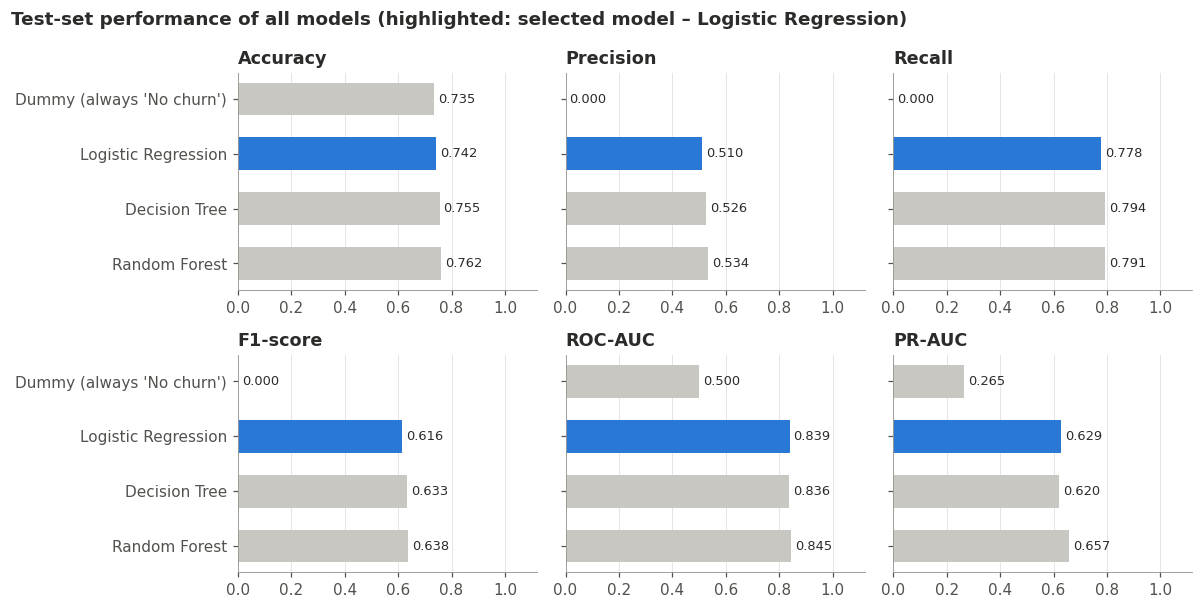

In [56]:
fig = mp.plot_model_comparison(test_table[["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]].astype(float),
                               selected_name)
ep.save_fig(fig, "fig12_model_comparison.png")
plt.show()

**Figure 12 – interpretation** (test set: 1,409 customers, threshold 0.5)

| Model | ROC-AUC | Recall | Precision | F1 | Accuracy |
|---|---|---|---|---|---|
| Logistic Regression (selected) | 0.839 | 0.778 | 0.510 | 0.616 | 0.742 |
| Decision Tree | 0.836 | 0.794 | 0.526 | 0.633 | 0.755 |
| Random Forest | 0.845 | 0.791 | 0.534 | 0.638 | 0.762 |
| Dummy baseline | 0.500 | 0 | 0 | 0 | 0.735 |

- **All models are far better than the baseline.**
- **Honest observation:** on the test set the Random Forest is slightly ahead of Logistic Regression on every metric. The differences are small: ROC-AUC +0.006, F1 +0.02. Section 6.6 checks whether they are larger than the uncertainty of a 1,409-customer test set.
- Accuracy only rises from 73.5% (baseline) to about 74–76%. Accuracy hides the real improvement: the models now catch about **78–79% of churners instead of 0%**.

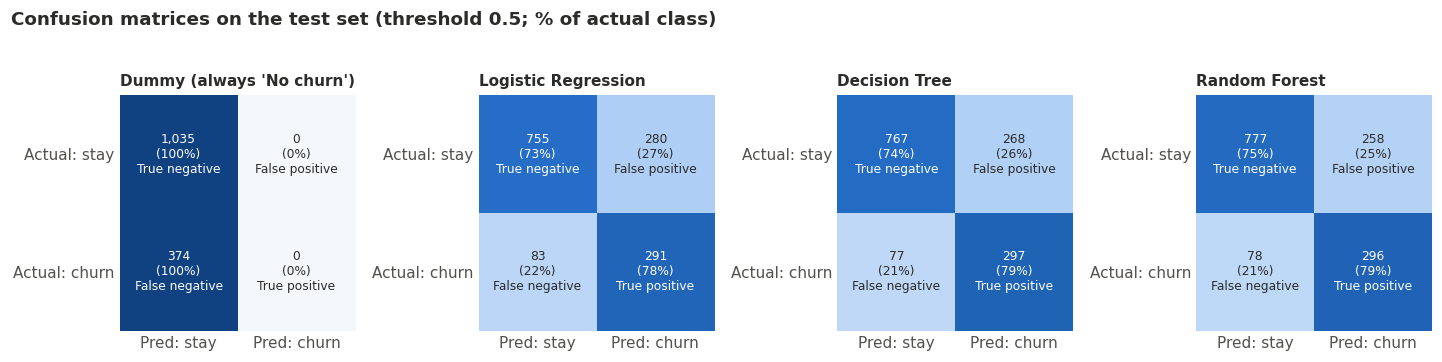

In [57]:
fig = mp.plot_confusion_matrices(test_results)
ep.save_fig(fig, "fig13_confusion_matrices.png")
plt.show()

**Figure 13 – interpretation** (actual vs predicted classes, test set)

For the selected **Logistic Regression**:
- **291 of 374 churners are correctly flagged** (true positives, 78% recall).
- **83 churners are missed** (false negatives). These are lost customers the company would not try to retain.
- **280 of 1,035 loyal customers are flagged** (false positives, 27%). These would receive a retention offer they did not need.
- About **one in two flagged customers is a real churner** (precision 0.51). For comparison, about one in four of a randomly chosen group would be.

**Business reading:** the model trades about 280 unnecessary offers for catching 291 churners. Whether that is worthwhile depends on the cost of an offer compared with the value of a retained customer. The threshold (Section 6.8) can be moved to change this trade-off. The three models make very similar errors: the two tree models catch 5–6 more churners and raise 12–22 fewer false alarms than Logistic Regression.

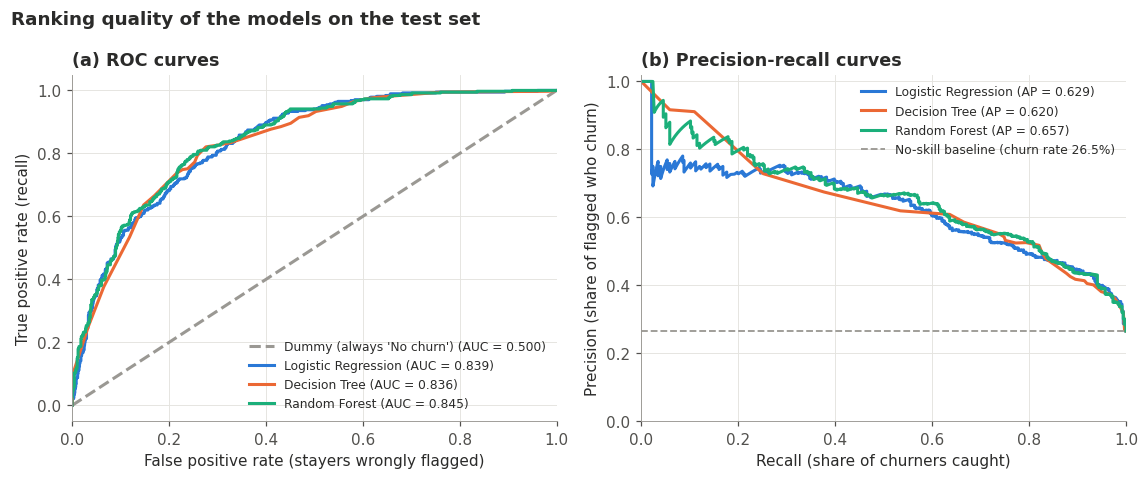

In [58]:
fig = mp.plot_roc_pr_curves(y_test.to_numpy(), test_probas)
ep.save_fig(fig, "fig14_roc_pr_curves.png")
plt.show()

**Figure 14 – interpretation**
- **(a) ROC curves.** All three models lie far above the diagonal (the guessing baseline) and almost on top of each other. Their ability to rank customers by risk is practically the same.
- **(b) Precision-recall curves.** These show the trade-off for the minority churn class.
  - At around 50% recall, all models have precision of about 0.65. In other words, about two-thirds of the highest-risk customers really churn.
  - Precision falls towards the 26.5% baseline as recall approaches 100%.
  - The Random Forest has a small advantage at the very top of the ranking (low recall, high precision).

### 6.6 How certain are these test scores? Bootstrap confidence intervals
**What:** one test set of 1,409 customers is only one sample. We **resample the test customers with replacement 1,000 times** and recompute ROC-AUC each time. The middle 95% of those values gives a **95% confidence interval**.

To compare two models fairly we use a **paired bootstrap**: both models are scored on the *same* resampled customers each time.

In [59]:
ci_rows = []
for name in searches:
    low, high = md.bootstrap_ci(y_test, test_probas[name])
    ci_rows.append({"model": name, "test_roc_auc": test_table.loc[name, "roc_auc"],
                    "ci_95_low": low, "ci_95_high": high})
auc_ci = pd.DataFrame(ci_rows).set_index("model")

best_cv_name = ranking.index[0]
comparisons = []
for other in [m for m in searches if m != selected_name]:
    mean_diff, (d_low, d_high) = md.paired_bootstrap_difference(y_test, test_probas[other], test_probas[selected_name])
    comparisons.append({"comparison": f"{other} minus {selected_name}", "mean_auc_difference": mean_diff,
                        "ci_95_low": d_low, "ci_95_high": d_high, "ci_includes_zero": d_low <= 0 <= d_high})
auc_diff = pd.DataFrame(comparisons).set_index("comparison")
auc_ci.to_csv(config.TABLE_DIR / "t30_test_auc_confidence_intervals.csv")
auc_diff.to_csv(config.TABLE_DIR / "t31_test_auc_paired_differences.csv")
display(auc_ci.round(3))
auc_diff.round(3)

,test_roc_auc,ci_95_low,ci_95_high
model,,,
Logistic Regression,0.839,0.815,0.859
Decision Tree,0.836,0.812,0.857
Random Forest,0.845,0.823,0.866


,mean_auc_difference,ci_95_low,ci_95_high,ci_includes_zero
comparison,,,,
Decision Tree minus Logistic Regression,-0.003,-0.017,0.011,True
Random Forest minus Logistic Regression,0.006,-0.001,0.014,True


**Interpretation**
- The **95% confidence interval** for Logistic Regression's test ROC-AUC is about **0.815 to 0.859**.
- The intervals of all three models overlap heavily.
- In the **paired comparison**, Random Forest minus Logistic Regression = **+0.006**, with a 95% CI of **−0.001 to +0.014**. The interval **includes zero**, so the test set provides no statistically reliable evidence that the Random Forest ranks customers better. The same holds for the Decision Tree.

This supports selecting the simpler, interpretable model. Its cost in predictive performance is at most about one percentage point of AUC, and possibly nothing.

### 6.7 Overfitting check
We compare how well each model fits the data it was trained on with how well it predicts new data:
- **CV training AUC:** score on the folds used for fitting.
- **CV validation AUC:** score on the held-out fold.
- **Test AUC:** score on the untouched test set.

A large drop from training to validation or test indicates **overfitting**, meaning the model memorised noise.

In [60]:
overfit = pd.DataFrame({
    "cv_train_roc_auc": cv_table.loc[list(searches), "cv_train_roc_auc_mean"],
    "cv_validation_roc_auc": cv_table.loc[list(searches), "cv_roc_auc_mean"],
    "test_roc_auc": test_table.loc[list(searches), "roc_auc"].astype(float),
})
overfit["gap_train_minus_validation"] = overfit["cv_train_roc_auc"] - overfit["cv_validation_roc_auc"]
overfit["gap_validation_minus_test"] = overfit["cv_validation_roc_auc"] - overfit["test_roc_auc"]
overfit.to_csv(config.TABLE_DIR / "t32_overfitting_check.csv")
overfit.round(3)

,cv_train_roc_auc,cv_validation_roc_auc,test_roc_auc,gap_train_minus_validation,gap_validation_minus_test
model,,,,,
Logistic Regression,0.848,0.845,0.839,0.003,0.006
Decision Tree,0.853,0.831,0.836,0.021,-0.004
Random Forest,0.890,0.849,0.845,0.041,0.004


**Interpretation**

| Model | Training → validation gap (AUC) | Overfitting |
|---|---|---|
| Logistic Regression | 0.003 | Virtually none |
| Decision Tree | 0.021 | Mild |
| Random Forest | 0.041 | Moderate (training AUC 0.890) |

- The Random Forest fits the training data noticeably better than new data, which is typical of flexible models even with depth limits.
- **For every model, the test AUC is within 0.006 of the CV validation AUC.** The CV estimates were therefore reliable, and none of the models collapses on unseen customers.
- The restricted tree settings chosen by grid search (shallow trees, large leaves) kept overfitting under control.

### 6.8 Choosing a decision threshold for the selected model
**What:** the model outputs a churn **probability**. A threshold turns it into a yes/no decision (e.g. "flag if probability ≥ 0.5"). Lowering the threshold catches more churners (higher recall) but flags more loyal customers (lower precision).

**How (leakage-free):**
- We use `cross_val_predict` to get **out-of-fold probabilities for the training customers only**. Each customer's probability comes from a model that did not see them.
- We pick the threshold with the highest F1 on those predictions.
- The test set is used only afterwards, to report results.

Threshold with the highest cross-validated F1: 0.55


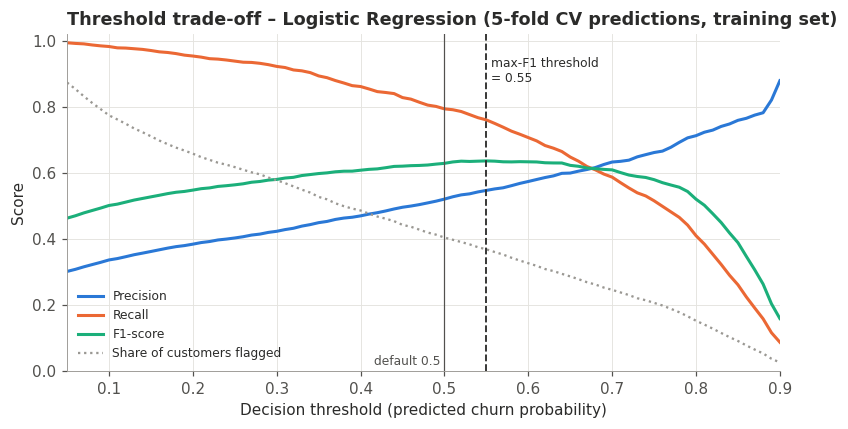

,accuracy,precision,recall,f1,roc_auc,pr_auc,TN,FP,FN,TP,customers_flagged
threshold 0.50 (default),0.742,0.510,0.778,0.616,0.839,0.629,755.0,280.0,83.0,291.0,571.0
threshold 0.55 (max CV F1),0.753,0.525,0.743,0.615,0.839,0.629,783.0,252.0,96.0,278.0,530.0


In [61]:
oof_proba = cross_val_predict(clone(selected_model), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
thresholds = md.threshold_table(y_train.to_numpy(), oof_proba)
thresholds.to_csv(config.TABLE_DIR / "t33_threshold_tradeoff_cv.csv", index=False)
best_threshold = float(thresholds.loc[thresholds["f1"].idxmax(), "threshold"])
print(f"Threshold with the highest cross-validated F1: {best_threshold:.2f}")

fig = mp.plot_threshold_tradeoff(thresholds, best_threshold, selected_name)
ep.save_fig(fig, "fig15_threshold_tradeoff.png")
plt.show()

operating = pd.DataFrame({
    f"threshold 0.50 (default)": md.classification_metrics(y_test, test_probas[selected_name], 0.5),
    f"threshold {best_threshold:.2f} (max CV F1)": md.classification_metrics(y_test, test_probas[selected_name], best_threshold),
}).T
operating["customers_flagged"] = operating["TP"] + operating["FP"]
operating.to_csv(config.TABLE_DIR / "t34_selected_model_operating_points.csv")
operating.round(3)

**Figure 15 – interpretation**
- As the threshold rises, **precision rises and recall falls**. Fewer customers are flagged, but a larger share of them are real churners.
- F1 is **almost flat between about 0.45 and 0.65**. The highest cross-validated F1 occurs at **0.55**, but it is practically the same as at 0.50.
- **On the test set, the two thresholds perform almost identically:**

| Threshold | Customers flagged | Churners caught (recall) | Precision |
|---|---|---|---|
| 0.50 | 571 | 291 (77.8%) | 0.51 |
| 0.55 | 530 | 278 (74.3%) | 0.52 |

**Recommendation:** keep the default **0.50**, but treat the threshold as a **business setting**, not a fixed part of the model.
- If the retention budget is small, raise the threshold and contact only the highest-risk customers (higher precision).
- If losing customers is very costly, lower it (higher recall).
- Ideally the company would choose the threshold from the actual cost of an offer and the value of a retained customer.

### 6.9 Save the final model
The full Pipeline (preprocessing and model) is saved. It can be loaded later and applied directly to raw customer records with the same columns.

In [62]:
config.MODEL_DIR.mkdir(parents=True, exist_ok=True)
model_path = config.MODEL_DIR / "final_churn_model.joblib"

# Raw columns the model actually uses (the ColumnTransformer drops everything else)
used_columns = [col for _, _, cols in selected_model.named_steps["prep"].transformers_[:2] for col in cols]
if selected_name == "Logistic Regression":
    assert not set(config.LR_EXCLUDED_FEATURES) & set(used_columns), "excluded charge columns reached the model"
print(f"Columns used by the final model ({len(used_columns)}): {used_columns}")
joblib.dump(selected_model, model_path)

final_metrics = {
    "selected_model": selected_name,
    "selection_rule": "highest mean 5-fold CV ROC-AUC; within 0.01 prefer the more interpretable model",
    "best_params": {k.replace("model__", ""): v for k, v in searches[selected_name].best_params_.items()},
    "columns_used": used_columns,
    "model_columns_after_encoding": list(selected_model.named_steps["prep"].get_feature_names_out()),
    "cv_roc_auc_mean": float(cv_table.loc[selected_name, "cv_roc_auc_mean"]),
    "test_metrics_threshold_0.5": {k: float(v) for k, v in test_results[selected_name].items()},
    "recommended_threshold_max_cv_f1": best_threshold,
    "random_state": config.RANDOM_STATE,
    "sklearn_version": sklearn.__version__,
}
with open(config.MODEL_DIR / "final_model_metrics.json", "w") as fh:
    json.dump(final_metrics, fh, indent=2)

reloaded = joblib.load(model_path)
assert np.allclose(reloaded.predict_proba(X_test)[:, 1], test_probas[selected_name])
print(f"Saved {model_path.relative_to(PROJECT_ROOT)} and reloaded it successfully.")

Columns used by the final model (17): ['tenure', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Saved outputs/models/final_churn_model.joblib and reloaded it successfully.


### 6.10 Modelling summary
| Item | Result |
|---|---|
| Selected model | **Logistic Regression** (C = 1, balanced class weights, 17 input features) |
| Why selected | CV ROC-AUC 0.845, within 0.01 of the best (Random Forest 0.849); most interpretable; least overfitting |
| Test performance (threshold 0.5) | ROC-AUC 0.839 (95% CI 0.815–0.859), recall 0.778, precision 0.510, F1 0.616, accuracy 0.742 |
| vs baseline | ROC-AUC 0.50 → 0.84; churners caught 0% → 78% |
| Alternative | Random Forest is marginally better on the test set (AUC +0.006). The difference is not statistically reliable, and the model is harder to explain. |
| Saved artefacts | `outputs/models/final_churn_model.joblib` (full Pipeline) and `final_model_metrics.json` |

**Leakage safeguards:**
- All tuning, threshold selection and design checks used **training data only**, and the test set was used once.
- Preprocessing was re-fitted inside every CV fold through the Pipeline.

## 7. Model interpretation
**What:** explain *which* customer characteristics drive the model's churn predictions, and how.

**Why:** a churn model is only useful if the business can understand and trust it. Interpretation also checks that the model relies on sensible patterns, the same ones found in EDA, rather than on artefacts.

We use three complementary tools:

| Tool | Model | Answers |
|---|---|---|
| Odds ratios | Logistic Regression | Direction and size of each feature's association, holding the others constant |
| Permutation importance | Logistic Regression and Random Forest | How much test performance depends on each feature |
| Shallow decision tree | Decision Tree (depth 3) | Simple if/then rules a manager can read |

> All interpretations describe **associations learned from observational data**, not causal effects.

In [63]:
from sklearn.metrics import roc_auc_score
from src import interpretation as it

lr_model = searches["Logistic Regression"].best_estimator_
rf_model = searches["Random Forest"].best_estimator_
references = it.reference_levels(lr_model)
tenure_sd = lr_model.named_steps["prep"].named_transformers_["num"].named_steps["scale"].scale_[0]
print("Reference (baseline) category for each variable:")
for var, ref in references.items():
    print(f"  {var:17s} -> {ref}")
print(f"\nTenure is standardised: 1 SD = {tenure_sd:.1f} months")

Reference (baseline) category for each variable:
  gender            -> Female
  SeniorCitizen     -> No
  Partner           -> No
  Dependents        -> No
  PhoneService      -> No
  MultipleLines     -> No
  InternetService   -> DSL
  OnlineSecurity    -> No
  OnlineBackup      -> No
  DeviceProtection  -> No
  TechSupport       -> No
  StreamingTV       -> No
  StreamingMovies   -> No
  Contract          -> Month-to-month
  PaperlessBilling  -> No
  PaymentMethod     -> Bank transfer (automatic)

Tenure is standardised: 1 SD = 24.6 months


### 7.1 Logistic regression odds ratios
**How to read an odds ratio (OR):**
- **OR = 2** means the odds of churning are twice as high as for the reference category, *for customers who are otherwise identical*.
- **OR = 0.5** means the odds are halved.
- **OR = 1** means no difference.

**Uncertainty:** the 95% confidence intervals come from refitting the whole pipeline on 200 bootstrap resamples of the **training** set. If an interval includes 1, the direction of the effect is uncertain.

*Note:* because of balanced class weighting the model's intercept is shifted, but the odds ratios of the features (their relative effects) are interpreted as usual.

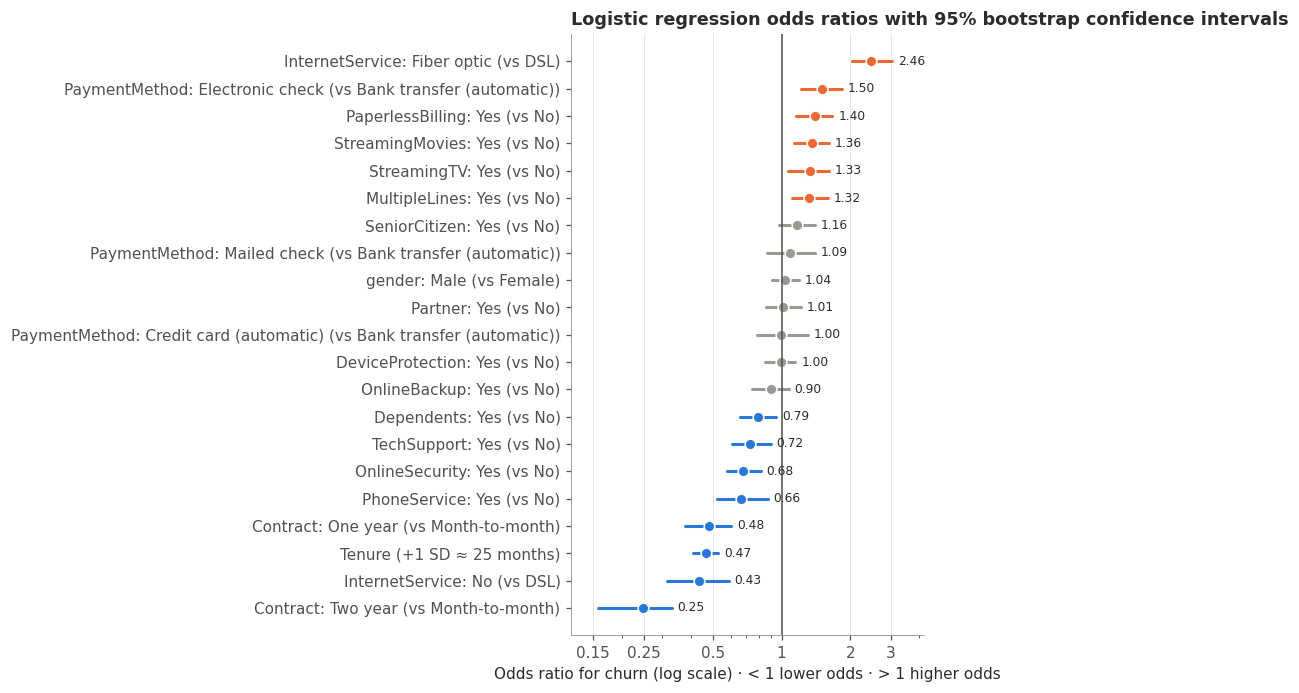

,label,odds_ratio,or_ci_low,or_ci_high,direction
16,Contract: Two year (vs Month-to-month),0.25,0.16,0.33,lower churn odds
8,InternetService: No (vs DSL),0.43,0.32,0.59,lower churn odds
0,Tenure (+1 SD ≈ 25 months),0.47,0.41,0.53,lower churn odds
15,Contract: One year (vs Month-to-month),0.48,0.38,0.60,lower churn odds
5,PhoneService: Yes (vs No),0.66,0.52,0.87,lower churn odds
9,OnlineSecurity: Yes (vs No),0.68,0.58,0.81,lower churn odds
12,TechSupport: Yes (vs No),0.72,0.60,0.89,lower churn odds
4,Dependents: Yes (vs No),0.79,0.66,0.95,lower churn odds
10,OnlineBackup: Yes (vs No),0.90,0.75,1.07,unclear
11,DeviceProtection: Yes (vs No),1.00,0.85,1.15,unclear


In [64]:
or_table = it.odds_ratio_table(lr_model).merge(it.bootstrap_odds_ratios(lr_model, X_train, y_train, n_boot=200),
                                                on="feature")
or_table["label"] = [mp.readable_feature(f, references) for f in or_table["feature"]]
or_table["ci_includes_1"] = (or_table["or_ci_low"] <= 1) & (or_table["or_ci_high"] >= 1)
or_table["direction"] = np.where(or_table["ci_includes_1"], "unclear",
                                 np.where(or_table["odds_ratio"] > 1, "higher churn odds", "lower churn odds"))
or_table.to_csv(config.TABLE_DIR / "t35_odds_ratios.csv", index=False)

fig = mp.plot_odds_ratios(or_table)
ep.save_fig(fig, "fig16_odds_ratios.png")
plt.show()
or_table.sort_values("odds_ratio")[["label", "odds_ratio", "or_ci_low", "or_ci_high", "direction"]].round(2)

**Figure 16 – interpretation** (holding all other features constant)

**Associated with lower churn odds (blue):**

| Feature | Odds ratio |
|---|---|
| **Two-year contract** vs month-to-month | **0.25** (about four times lower odds) |
| One-year contract | 0.48 |
| **Each extra 25 months of tenure** | **0.47** |
| No internet service vs DSL | 0.43 |
| Online security | 0.68 |
| Tech support | 0.72 |
| Phone service | 0.66 |
| Dependents | 0.79 |

**Associated with higher churn odds (orange):**

| Feature | Odds ratio |
|---|---|
| **Fiber optic vs DSL** | **2.46** |
| **Electronic check** vs automatic bank transfer | **1.50** |
| Paperless billing | 1.40 |
| Streaming TV / movies and multiple lines | 1.32–1.36 |

**Unclear (grey, the CI includes 1):**
- gender, partner, senior citizen (1.16, CI 0.98–1.40)
- online backup, device protection
- credit card and mailed check (vs bank transfer)

**What changes compared with the one-at-a-time tests (Section 5):**
- **Senior citizen** and **partner** were significant on their own but are **not** once contract, tenure and services are accounted for. Their raw differences are largely explained by those other factors.
- **Streaming and multiple lines now show *higher* odds.** Because `MonthlyCharges` was removed, these paid add-ons partly carry the **price** signal: holding contract, tenure and internet type equal, customers paying for extra services churn somewhat more.
- This shows why multivariable models and univariate tests can tell different, complementary stories.

#### The fitted logistic regression equation
Logistic regression models the **log-odds** of churn as a weighted sum of the inputs:

log-odds(churn) = ln( p / (1 − p) ) = β₀ + β₁x₁ + β₂x₂ + …

The predicted probability is then p = 1 / (1 + e^(−log-odds)).

In our model:
- **Tenure** is standardised: z = (tenure − mean) / SD.
- **Each dummy** is 1 if the customer has that category, and 0 if they have the reference category.

In [65]:
lr_coefs = pd.Series(lr_model.named_steps["model"].coef_.ravel(),
                     index=lr_model.named_steps["prep"].get_feature_names_out())
lr_intercept = float(lr_model.named_steps["model"].intercept_[0])
scaler = lr_model.named_steps["prep"].named_transformers_["num"].named_steps["scale"]

ordered = lr_coefs.reindex(lr_coefs.abs().sort_values(ascending=False).index)
terms = [f"{coef:+.3f} × [{name}]" for name, coef in ordered.items()]
equation = "log-odds(churn) = " + f"{lr_intercept:+.3f}\n    " + "\n    ".join(terms)
equation += (f"\n\nwhere [tenure] = (tenure − {scaler.mean_[0]:.2f}) / {scaler.scale_[0]:.2f}, every other term is 1 if the "
             "customer has that category (0 = reference category), and p(churn) = 1 / (1 + exp(−log-odds)).\n"
             "Note: balanced class weights shift the intercept; use the model for ranking, not as calibrated probabilities.")
(config.TABLE_DIR / "t43_logistic_equation.txt").write_text(equation)
print(equation)

log-odds(churn) = -0.403
    -1.394 × [Contract_Two year]
    +0.899 × [InternetService_Fiber optic]
    -0.836 × [InternetService_No]
    -0.760 × [tenure]
    -0.731 × [Contract_One year]
    -0.408 × [PhoneService_Yes]
    +0.402 × [PaymentMethod_Electronic check]
    -0.389 × [OnlineSecurity_Yes]
    +0.334 × [PaperlessBilling_Yes]
    -0.323 × [TechSupport_Yes]
    +0.305 × [StreamingMovies_Yes]
    +0.282 × [StreamingTV_Yes]
    +0.275 × [MultipleLines_Yes]
    -0.240 × [Dependents_Yes]
    +0.151 × [SeniorCitizen_Yes]
    -0.109 × [OnlineBackup_Yes]
    +0.083 × [PaymentMethod_Mailed check]
    +0.038 × [gender_Male]
    +0.013 × [Partner_Yes]
    -0.004 × [DeviceProtection_Yes]
    -0.001 × [PaymentMethod_Credit card (automatic)]

where [tenure] = (tenure − 32.48) / 24.57, every other term is 1 if the customer has that category (0 = reference category), and p(churn) = 1 / (1 + exp(−log-odds)).
Note: balanced class weights shift the intercept; use the model for ranking, not as c

#### Classical coefficient table (statsmodels)
The previous-year report showed a regression summary with standard errors and p-values. For logistic regression the equivalent is `statsmodels` **Logit**.
- We fit it on exactly the same training design (same 21 columns).
- It is **unpenalised and unweighted**, so it is a *supplementary inference model* for p-values and confidence intervals.
- The scikit-learn pipeline remains the predictive model.
- We compare the two sets of odds ratios to check they agree.

In [66]:
import statsmodels.api as sm

design_train = pd.DataFrame(lr_model.named_steps["prep"].transform(X_train),
                            columns=lr_model.named_steps["prep"].get_feature_names_out(), index=X_train.index)
logit_fit = sm.Logit(y_train, sm.add_constant(design_train)).fit(disp=0)
ci95 = logit_fit.conf_int()
logit_summary = pd.DataFrame({
    "coef": logit_fit.params, "std_err": logit_fit.bse, "z": logit_fit.tvalues, "p_value": logit_fit.pvalues,
    "ci_low": ci95[0], "ci_high": ci95[1], "odds_ratio": np.exp(logit_fit.params),
    "odds_ratio_sklearn_model": np.exp(lr_coefs).reindex(logit_fit.params.index),
})
logit_summary.to_csv(config.TABLE_DIR / "t44_logit_summary.csv")
pd.DataFrame([{"mcfadden_pseudo_r2": logit_fit.prsquared, "log_likelihood": logit_fit.llf, "n": int(logit_fit.nobs),
               "terms_p_below_0.05": int((logit_fit.pvalues.drop("const") < 0.05).sum()),
               "n_terms": len(logit_fit.params) - 1}]).to_csv(config.TABLE_DIR / "t45_logit_fit_statistics.csv", index=False)

slopes = logit_summary.drop(index="const")
print(f"McFadden pseudo R² = {logit_fit.prsquared:.3f} | log-likelihood = {logit_fit.llf:.1f} | n = {int(logit_fit.nobs):,}")
print(f"Odds ratios, statsmodels vs final model: largest difference = "
      f"{(slopes['odds_ratio'] - slopes['odds_ratio_sklearn_model']).abs().max():.3f}, "
      f"correlation (log scale) = {np.corrcoef(np.log(slopes['odds_ratio']), np.log(slopes['odds_ratio_sklearn_model']))[0, 1]:.3f}")
print(f"Terms with p < 0.05: {int((slopes['p_value'] < 0.05).sum())} of {len(slopes)}")
logit_summary.assign(p_value=logit_summary["p_value"].map(format_p)).round(3)

McFadden pseudo R² = 0.285 | log-likelihood = -2331.3 | n = 5,634
Odds ratios, statsmodels vs final model: largest difference = 0.066, correlation (log scale) = 0.999
Terms with p < 0.05: 14 of 21


,coef,std_err,z,p_value,ci_low,ci_high,odds_ratio,odds_ratio_sklearn_model
const,-1.411,0.181,-7.797,< 0.001,-1.766,-1.056,0.244,NaN
tenure,-0.804,0.065,-12.416,< 0.001,-0.931,-0.677,0.448,0.468
gender_Male,0.022,0.073,0.303,0.762,-0.121,0.165,1.022,1.039
SeniorCitizen_Yes,0.142,0.095,1.493,0.135,-0.044,0.328,1.152,1.163
Partner_Yes,0.022,0.087,0.257,0.797,-0.148,0.192,1.023,1.013
Dependents_Yes,-0.237,0.101,-2.354,0.019,-0.434,-0.040,0.789,0.787
PhoneService_Yes,-0.467,0.142,-3.291,< 0.001,-0.745,-0.189,0.627,0.665
MultipleLines_Yes,0.324,0.088,3.669,< 0.001,0.151,0.497,1.383,1.317
InternetService_Fiber optic,0.918,0.103,8.907,< 0.001,0.716,1.120,2.504,2.458
InternetService_No,-0.835,0.156,-5.369,< 0.001,-1.140,-0.530,0.434,0.433


**Interpretation**
- **The two models agree.** The unpenalised statsmodels Logit gives almost the same odds ratios as our final model: the largest difference is about 0.07, and the correlation on the log scale is about 0.999. So the effects are not artefacts of regularisation or class weighting.
- **What changes is the intercept**, because balanced class weights move the model's baseline. This is why we use the model's scores for ranking.
- **The p-values match the bootstrap intervals in Figure 16:**
  - Significant: contract, tenure, internet type, electronic check, paperless billing, online security, tech support, dependents, phone service, multiple lines and the two streaming terms.
  - Gender, partner, senior citizen, online backup, device protection and the credit-card and mailed-check payment levels are not.
- **McFadden's pseudo R²** is the logistic counterpart of R². Values around 0.2–0.4 are usually considered a good fit for this measure. It is **not** comparable to the R² of a linear regression.

### 7.2 Permutation importance
**What:** shuffle one input column in the **test set**, breaking its link with churn, and measure how much ROC-AUC drops. This is repeated 20 times per column. A big drop means the model relies heavily on that column.

**Why this method:**
- It works for **any** model, so we can compare Logistic Regression and Random Forest on the same scale.
- Each categorical variable is shuffled as one unit.
- It avoids the known bias of the Random Forest's built-in "impurity" importance, which favours continuous and high-cardinality features (Strobl et al., 2007).

**Caveat:** when two columns contain the same information (tenure and TotalCharges), shuffling one costs little because the model can use the other. Correlated features therefore *share* importance.

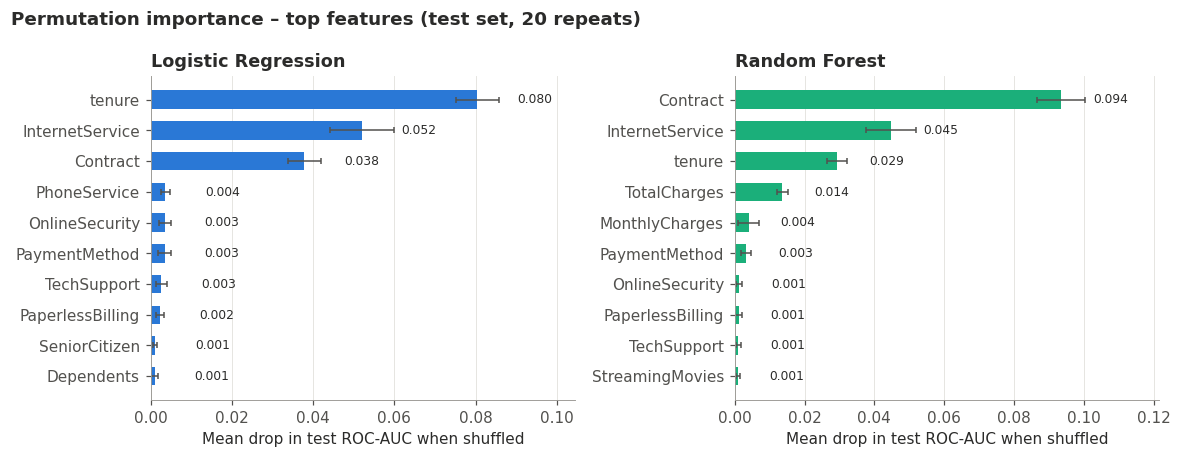

,feature,importance_mean_logistic_regression,importance_sd_logistic_regression,importance_mean_random_forest,importance_sd_random_forest
0,tenure,0.0804,0.0053,0.0293,0.0029
1,InternetService,0.0520,0.0078,0.0448,0.0071
2,Contract,0.0379,0.0041,0.0935,0.0068
3,PhoneService,0.0036,0.0011,0.0008,0.0002
4,OnlineSecurity,0.0035,0.0015,0.0014,0.0009
5,PaymentMethod,0.0034,0.0015,0.0033,0.0014
6,TechSupport,0.0026,0.0014,0.0011,0.0007
7,PaperlessBilling,0.0023,0.0011,0.0012,0.0010
8,SeniorCitizen,0.0012,0.0005,0.0008,0.0003
9,Dependents,0.0010,0.0008,0.0003,0.0004


In [67]:
perm_lr = it.permutation_importance_table(lr_model, X_test, y_test)
perm_rf = it.permutation_importance_table(rf_model, X_test, y_test)
perm = perm_lr.merge(perm_rf, on="feature", suffixes=("_logistic_regression", "_random_forest"))
perm.to_csv(config.TABLE_DIR / "t36_permutation_importance.csv", index=False)

fig = mp.plot_permutation_importance({"Logistic Regression": perm_lr, "Random Forest": perm_rf})
ep.save_fig(fig, "fig17_permutation_importance.png")
plt.show()
perm.round(4).head(10)

In [68]:
# For reference only: the Random Forest's built-in (impurity-based) importance.
# It is biased towards continuous/high-cardinality features, so we do not use it for conclusions.
rf_prep_names = rf_model.named_steps["prep"].get_feature_names_out()
impurity = (pd.DataFrame({"feature": rf_prep_names,
                          "impurity_importance": rf_model.named_steps["model"].feature_importances_})
            .sort_values("impurity_importance", ascending=False).reset_index(drop=True))
impurity.to_csv(config.TABLE_DIR / "t37_rf_impurity_importance.csv", index=False)
impurity.head(8).round(3)

,feature,impurity_importance
0,Contract_Month-to-month,0.200
1,tenure,0.140
2,Contract_Two year,0.101
3,TotalCharges,0.099
4,MonthlyCharges,0.089
5,InternetService_Fiber optic,0.077
6,PaymentMethod_Electronic check,0.054
7,InternetService_No,0.048


**Figure 17 – interpretation**
- **Both models depend mainly on the same three variables: contract, tenure and internet service.** Shuffling any of them clearly lowers test ROC-AUC. All other variables matter far less (drops below 0.005).
  - **Logistic Regression:** tenure (−0.080 AUC when shuffled), internet service (−0.052), contract (−0.038).
  - **Random Forest:** contract (−0.094), internet service (−0.045), tenure (−0.029), total charges (−0.014).
- **Why the order differs:** the Random Forest can also use `TotalCharges`, which is strongly correlated with tenure. The two share the "length of relationship" information, so each looks less important individually. Logistic Regression has only tenure, so all of that importance lands on one column.
- **Gender has zero importance in both models**, consistent with the statistical tests.
- The forest's built-in impurity importance (table above) ranks charges much higher. That measure is biased towards continuous features (Strobl et al., 2007), which is why we base conclusions on permutation importance.
- **Reliability check:** the top features agree with the EDA, the chi-square effect sizes and the odds ratios. Four independent views point to the same drivers.

### 7.3 Decision rules: a simplified depth-3 tree
The tuned decision tree (depth 5) has too many branches to read easily. For explanation, we fit a **depth-3 tree** with the same preprocessing and class weighting, at most 8 final groups, and report its performance so we know how much accuracy the simplification costs.

Depth-3 tree: CV ROC-AUC = 0.815 | test ROC-AUC = 0.815


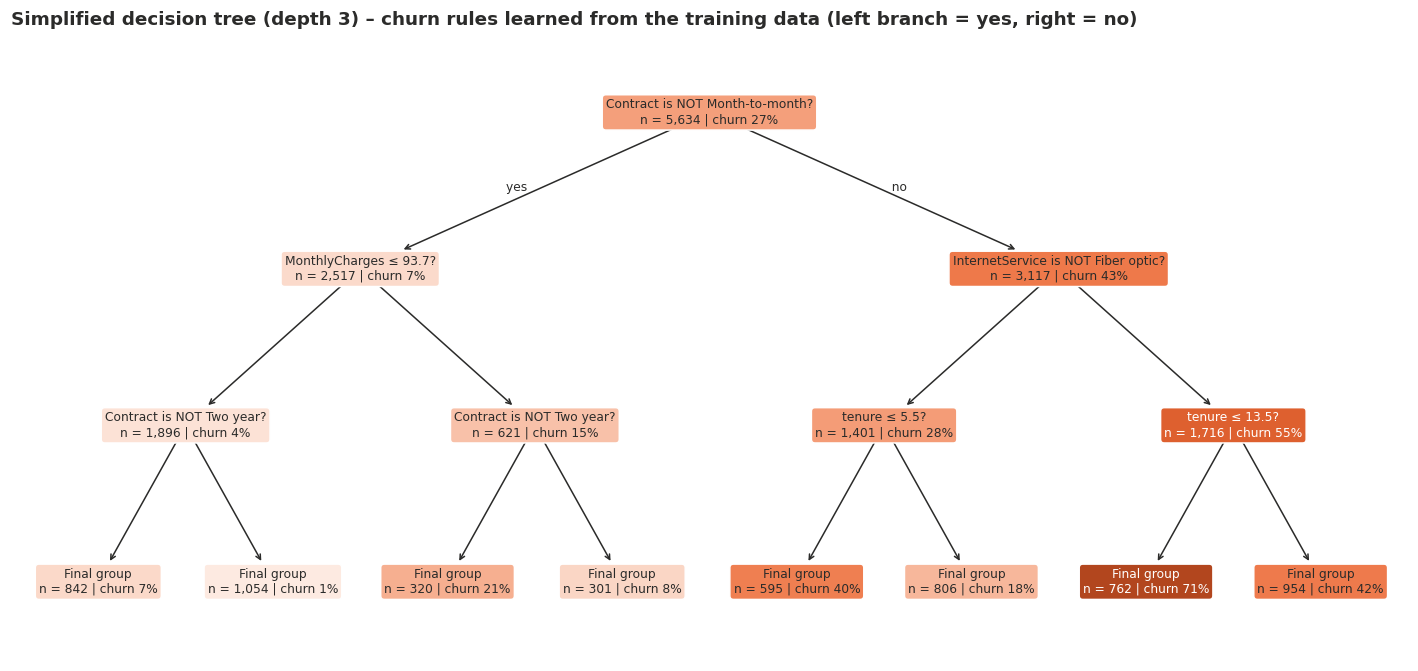

,rule,customers,churn_rate
0,Contract = Month-to-month AND InternetService = Fiber optic AND tenure <= 13.5,762,0.710
1,Contract = Month-to-month AND InternetService = Fiber optic AND tenure > 13.5,954,0.421
2,Contract = Month-to-month AND InternetService is not Fiber optic AND tenure <= 5.5,595,0.402
3,Contract is not Month-to-month AND MonthlyCharges > 93.7 AND Contract is not Two year,320,0.209
4,Contract = Month-to-month AND InternetService is not Fiber optic AND tenure > 5.5,806,0.182
5,Contract is not Month-to-month AND MonthlyCharges > 93.7 AND Contract = Two year,301,0.080
6,Contract is not Month-to-month AND MonthlyCharges <= 93.7 AND Contract is not Two year,842,0.071
7,Contract is not Month-to-month AND MonthlyCharges <= 93.7 AND Contract = Two year,1054,0.014


In [69]:
from sklearn.tree import DecisionTreeClassifier, export_text

simple_tree = md.make_pipeline(DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, class_weight="balanced",
                                                      random_state=config.RANDOM_STATE), scale_numeric=False)
simple_tree_cv_auc = cross_validate(simple_tree, X_train, y_train, cv=cv, scoring="roc_auc")["test_score"].mean()
simple_tree.fit(X_train, y_train)
simple_tree_test_auc = roc_auc_score(y_test, simple_tree.predict_proba(X_test)[:, 1])
print(f"Depth-3 tree: CV ROC-AUC = {simple_tree_cv_auc:.3f} | test ROC-AUC = {simple_tree_test_auc:.3f}")

fig, node_rates, node_sizes = mp.plot_simple_tree(simple_tree, X_train, y_train)
ep.save_fig(fig, "fig18_decision_tree_rules.png")
plt.show()

rules_text = export_text(simple_tree.named_steps["model"],
                         feature_names=list(simple_tree.named_steps["prep"].get_feature_names_out()))
(config.TABLE_DIR / "t38_decision_tree_rules.txt").write_text(rules_text)
tree_leaves = it.tree_leaf_table(simple_tree, X_train, y_train)
tree_leaves.insert(0, "simple_tree_cv_auc", simple_tree_cv_auc)
tree_leaves.insert(1, "simple_tree_test_auc", simple_tree_test_auc)
tree_leaves.to_csv(config.TABLE_DIR / "t38_decision_tree_leaves.csv", index=False)
pd.set_option("display.max_colwidth", 140)
tree_leaves[["rule", "customers", "churn_rate"]].round(3)

**Figure 18 – interpretation** (training customers; left = yes, right = no)

| Rule | Customers | Churn rate |
|---|---|---|
| **Highest risk:** month-to-month **and** fiber optic **and** tenure ≤ 13 months | 762 | **71%** |
| Month-to-month **and** not fiber **and** tenure ≤ 5 months | 595 | 40% |
| Month-to-month **and** fiber **and** tenure > 13 months | 954 | 42% |
| **Lowest risk:** two-year contract with monthly charges ≤ 93.7 USD | 1,054 | **1%** |

- The tree splits **first on contract type**, then on internet type or charges, then on tenure. This is the same hierarchy found by the other methods.
- The depth-3 tree is slightly weaker (test ROC-AUC 0.815 vs 0.836 for the tuned tree). For presenting rules to managers, that is a reasonable trade-off.

### 7.4 Actual vs predicted: how well does the risk ranking work in practice?
**Cumulative gains:**
1. Sort test customers from highest to lowest predicted risk.
2. Ask: if the retention team contacts only the top X%, what share of all churners would they reach?

Random targeting reaches X% of churners by contacting X% of customers.

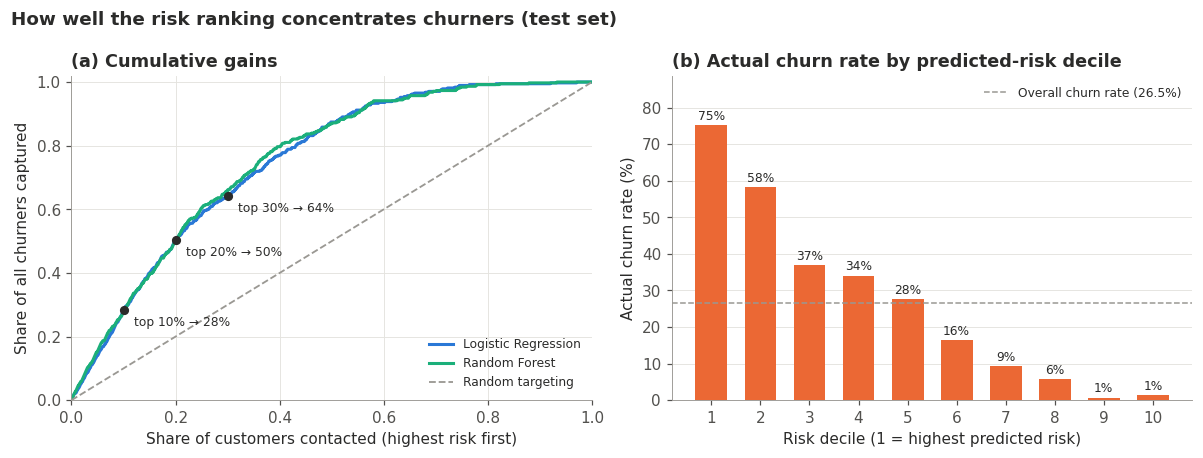

,customers,churners,mean_predicted_probability,actual_churn_rate,cumulative_share_of_customers,cumulative_share_of_churners_captured,lift
decile,,,,,,,
1,141,106,0.879,0.752,0.1,0.283,2.832
2,141,82,0.800,0.582,0.2,0.503,2.191
3,141,52,0.707,0.369,0.3,0.642,1.389
4,141,48,0.585,0.340,0.4,0.770,1.283
5,141,39,0.447,0.277,0.5,0.874,1.042
6,140,23,0.328,0.164,0.6,0.936,0.619
7,141,13,0.211,0.092,0.7,0.971,0.347
8,141,8,0.120,0.057,0.8,0.992,0.214
9,141,1,0.064,0.007,0.9,0.995,0.027


In [70]:
gains = it.gains_table(y_test, test_probas[selected_name])
gains.to_csv(config.TABLE_DIR / "t39_gains_table.csv")
fig = mp.plot_gains(y_test, {"Logistic Regression": test_probas["Logistic Regression"],
                             "Random Forest": test_probas["Random Forest"]}, gains)
ep.save_fig(fig, "fig19_gains_and_deciles.png")
plt.show()
gains.round(3)

**Figure 19 – interpretation** (actual vs predicted, test set)
- **(a)** Contacting customers in order of predicted risk reaches churners much faster than random targeting:

| Customers contacted (highest risk first) | Share of all churners reached |
|---|---|
| Top 10% | 28% |
| Top 20% | **50%** |
| Top 30% | 64% |

  Random targeting would reach 10%, 20% and 30%.
- **(b)** The actual churn rate falls steadily from **75% in the highest-risk decile** (2.8 times the average) to about 1% in the lowest two deciles. The model's ranking is consistent across its whole range.
- **Note on probabilities:** because of balanced class weighting, predicted probabilities are higher than the true churn rates. For example, the top decile averages 0.88 predicted vs 0.75 actual. The scores should therefore be used to **rank** customers, not read as exact probabilities. If calibrated probabilities were needed, the model could be re-calibrated on training data.

### 7.5 Error analysis: which churners does the model miss?
We compare the profiles of correctly flagged churners (true positives), missed churners (false negatives) and wrongly flagged loyal customers (false positives) in the test set.

In [71]:
test_view = clean.loc[X_test.index].copy()
pred = (test_probas[selected_name] >= 0.5).astype(int)
outcome = np.select([(y_test == 1) & (pred == 1), (y_test == 1) & (pred == 0),
                     (y_test == 0) & (pred == 1), (y_test == 0) & (pred == 0)],
                    ["True positive (churn caught)", "False negative (churn missed)",
                     "False positive (false alarm)", "True negative"],
                    default="Other")   # text default: required by numpy 2.x when the choices are text
test_view["outcome"] = outcome
error_profile = test_view.groupby("outcome").agg(
    customers=("tenure", "size"),
    median_tenure_months=("tenure", "median"),
    mean_monthly_charges=("MonthlyCharges", "mean"),
    pct_month_to_month=("Contract", lambda s: (s.dropna() == "Month-to-month").mean() * 100),
    pct_fiber_optic=("InternetService", lambda s: (s == "Fiber optic").mean() * 100),
    pct_electronic_check=("PaymentMethod", lambda s: (s == "Electronic check").mean() * 100),
    pct_tech_support=("TechSupport", lambda s: (s == "Yes").mean() * 100),
).loc[["True positive (churn caught)", "False negative (churn missed)",
       "False positive (false alarm)", "True negative"]]
error_profile.to_csv(config.TABLE_DIR / "t40_error_analysis.csv")
error_profile.round(1)

,customers,median_tenure_months,mean_monthly_charges,pct_month_to_month,pct_fiber_optic,pct_electronic_check,pct_tech_support
outcome,,,,,,,
True positive (churn caught),291,6.0,76.5,97.2,78.0,64.3,10.0
False negative (churn missed),83,30.0,59.7,55.4,30.1,22.9,37.3
False positive (false alarm),280,16.0,76.3,93.9,69.3,55.7,21.4
True negative,755,49.0,55.3,24.0,22.1,14.8,36.4


**Interpretation: who does the model miss?**

| Group | Median tenure | Month-to-month | Fiber | Tech support |
|---|---|---|---|---|
| **Missed churners (false negatives, 83)** | 30 months | 55% | 30% | 37% |
| Caught churners (true positives, 291) | 6 months | 97% | 78% | 10% |
| Loyal customers (true negatives) | 49 months | 24% | 22% | 36% |

- Missed churners look **much more like loyal customers** than like typical churners.
- They probably leave for reasons **not recorded in the data**, such as competitor offers, relocation or a service problem.
- **False alarms (false positives)** have a high-risk profile (94% month-to-month, 69% fiber) but stayed. For them a retention offer may be unnecessary, but they are genuinely at elevated risk.

**Implication:** adding data such as complaints, support-call history, network quality or competitor pricing would be the most promising way to catch the "surprise" churners.

## 8. Findings, recommendations and limitations
### 8.1 Answer to the research question

**Which characteristics are most strongly associated with churn?**
1. **Contract type** has the strongest association. Month-to-month churn is 42.7% vs 2.8% on two-year contracts (V = 0.41; OR two-year = 0.25).
2. **Tenure:** new customers churn most (47.5% in the first year; rank-biserial r = −0.48; OR 0.47 per 25 months).
3. **Internet service:** fiber-optic customers churn more even after adjusting for other factors (41.9%; OR 2.46 vs DSL).
4. **Payment and billing:** electronic check (45.3%; OR 1.50) and paperless billing (OR 1.40).
5. **Protective add-ons:** online security and tech support are associated with lower churn (ORs 0.68 and 0.72). Streaming add-ons are not.
6. **Weak or no association:** gender shows none. Once services and contract are accounted for, partner and senior status show no clear effect.

**How effectively can machine learning predict churn?**
- **Moderately well.** The selected logistic regression reaches a **test ROC-AUC of 0.839** (95% CI 0.815–0.859) and catches **78% of churners** at a precision of 0.51.
- Contacting just the **top 20%** of customers by predicted risk reaches **half of all churners**.
- Random Forest and Decision Tree performed similarly (differences within statistical uncertainty).
- About one in five churners remains hard to predict from the available variables.

### 8.2 Retention recommendations (based on the evidence above)
Each recommendation is linked to the evidence behind it. The model-based figures come from the executed code.

In [72]:
or_lookup = or_table.set_index("feature")["odds_ratio"]
cr = category_rates.set_index(["variable", "level"])["churn_rate"]
top20 = gains.loc[gains["cumulative_share_of_customers"].round(2) == 0.2, "cumulative_share_of_churners_captured"].iloc[0]
top30 = gains.loc[gains["cumulative_share_of_customers"].round(2) == 0.3, "cumulative_share_of_churners_captured"].iloc[0]

recommendations = pd.DataFrame([
    ["1. Move month-to-month customers onto longer contracts",
     f"Churn {cr[('Contract', 'Month-to-month')]:.1f}% vs {cr[('Contract', 'Two year')]:.1f}% (two-year); "
     f"OR two-year vs month-to-month = {or_lookup['Contract_Two year']:.2f}",
     "Offer loyalty discounts or added benefits for switching to 1- or 2-year plans, especially in the first year"],
    ["2. Strengthen onboarding in the first 12 months",
     f"Churn {cr[('tenure_group', '0–12')]:.1f}% in the first year vs {cr[('tenure_group', '49–72')]:.1f}% after 4 years; "
     f"OR per +1 SD tenure = {or_lookup['tenure']:.2f}",
     "Welcome calls, early check-ins and service-quality follow-ups for new customers"],
    ["3. Investigate the fiber-optic experience",
     f"Churn {cr[('InternetService', 'Fiber optic')]:.1f}% vs {cr[('InternetService', 'DSL')]:.1f}% (DSL); "
     f"OR fiber vs DSL = {or_lookup['InternetService_Fiber optic']:.2f} even after controlling for other factors",
     "Review fiber pricing, reliability and support; survey departing fiber customers"],
    ["4. Encourage automatic payment",
     f"Churn {cr[('PaymentMethod', 'Electronic check')]:.1f}% for electronic check vs "
     f"{cr[('PaymentMethod', 'Credit card (automatic)')]:.1f}% for automatic credit card; "
     f"OR = {or_lookup['PaymentMethod_Electronic check']:.2f} vs bank transfer",
     "Small incentives to switch from electronic check to automatic bank or card payment"],
    ["5. Promote security and support add-ons",
     f"Internet customers: churn with/without OnlineSecurity {addon_table.loc['OnlineSecurity: with', 'churn_rate']:.1f}% / "
     f"{addon_table.loc['OnlineSecurity: without', 'churn_rate']:.1f}%; TechSupport "
     f"{addon_table.loc['TechSupport: with', 'churn_rate']:.1f}% / {addon_table.loc['TechSupport: without', 'churn_rate']:.1f}%; "
     f"ORs {or_lookup['OnlineSecurity_Yes']:.2f} and {or_lookup['TechSupport_Yes']:.2f}",
     "Bundle or offer free trials of online security and tech support, prioritising high-risk customers"],
    ["6. Use the model to prioritise, not to decide alone",
     f"Contacting the top 20% riskiest customers reaches {top20:.0%} of churners (top 30%: {top30:.0%})",
     "Score customers monthly, contact the highest-risk group first, and size the group to the retention budget"],
    ["7. Measure impact with a controlled trial",
     "The data are observational, so the effect of interventions is unknown",
     "Randomly assign retention offers within the high-risk group (A/B test) to measure their real effect before scaling"],
], columns=["recommendation", "evidence", "suggested action"])
recommendations.to_csv(config.TABLE_DIR / "t41_recommendations.csv", index=False)
pd.set_option("display.max_colwidth", 160)
recommendations

,recommendation,evidence,suggested action
0,1. Move month-to-month customers onto longer contracts,Churn 42.7% vs 2.8% (two-year); OR two-year vs month-to-month = 0.25,"Offer loyalty discounts or added benefits for switching to 1- or 2-year plans, especially in the first year"
1,2. Strengthen onboarding in the first 12 months,Churn 47.5% in the first year vs 9.5% after 4 years; OR per +1 SD tenure = 0.47,"Welcome calls, early check-ins and service-quality follow-ups for new customers"
2,3. Investigate the fiber-optic experience,Churn 41.9% vs 19.0% (DSL); OR fiber vs DSL = 2.46 even after controlling for other factors,"Review fiber pricing, reliability and support; survey departing fiber customers"
3,4. Encourage automatic payment,Churn 45.3% for electronic check vs 15.2% for automatic credit card; OR = 1.50 vs bank transfer,Small incentives to switch from electronic check to automatic bank or card payment
4,5. Promote security and support add-ons,Internet customers: churn with/without OnlineSecurity 14.6% / 41.8%; TechSupport 15.2% / 41.6%; ORs 0.68 and 0.72,"Bundle or offer free trials of online security and tech support, prioritising high-risk customers"
5,"6. Use the model to prioritise, not to decide alone",Contacting the top 20% riskiest customers reaches 50% of churners (top 30%: 64%),"Score customers monthly, contact the highest-risk group first, and size the group to the retention budget"
6,7. Measure impact with a controlled trial,"The data are observational, so the effect of interventions is unknown",Randomly assign retention offers within the high-risk group (A/B test) to measure their real effect before scaling


### 8.3 Using the model responsibly
- **Decision support, not automation.** The model ranks customers for attention. Staff should decide on offers, and no customer should be penalised because of a score.
- **Fairness:**
  - Gender has no predictive value here, and the final logistic model does not use it in any meaningful way (OR ≈ 1). It could be removed entirely in production.
  - Age-related information (SeniorCitizen) should never be used to offer *worse* terms.
  - Outcomes should be checked periodically across customer groups.
- **Privacy:** customer data must be handled under the company's data-protection obligations, using only the data customers agreed to share.
- **Monitoring:**
  - Churn patterns change with prices, competitors and technology, so the model's performance should be **monitored monthly** and it should be **retrained** (e.g. quarterly) on recent data.
  - Data-quality checks like those in Section 1 should run on every new data load.
- **Probability scale:** use the scores for ranking. Re-calibrate before treating them as exact probabilities.

### 8.4 Limitations
1. **Observational data.** All findings are associations. We cannot conclude that changing a customer's contract or payment method would *cause* them to stay. A randomised trial is needed for that.
2. **Snapshot without timing.** Variables are recorded at one point in time, so we cannot tell whether, for example, contract changes happened before the churn decision.
3. **Limited features.** There is no information on complaints, service quality, network outages, competitor offers or customer satisfaction. This limits accuracy, as the missed-churner analysis shows.
4. **Data quality.** The file contained injected errors (duplicates, impossible values, invalid labels). These were repaired with documented rules, and affected customers' churn rate differed somewhat (31.7% vs 26.4%; not significant). A small residual effect cannot be ruled out.
5. **Single provider, sample data.** The data come from an IBM sample dataset describing one (fictional) US telecom provider. Results may not transfer to real operators or to other markets, such as Sri Lanka, without re-validation on local data.
6. **Model scope.** Only three model families were compared, with modest grids. Other methods (e.g. gradient boosting) might gain a little accuracy, but the near-identical performance of three very different models suggests the available information sets the limit, not the algorithm.
7. **Probability calibration.** Class weighting inflates predicted probabilities, so they should be used for ranking.

### 8.5 Conclusion
- **Data preparation.** The analysis followed a documented, leakage-safe workflow.
  - Raw-data problems were audited before any change.
  - Corrupted values were repaired with row-wise rules.
  - All learned preprocessing was confined to training-only Pipelines.
- **Consistent drivers.** EDA, statistical tests, odds ratios, permutation importance and decision rules all point to the same drivers of churn:
  - **short contracts**
  - **short tenure**
  - **fiber-optic service**
  - **electronic-check payment**
  - **the absence of security and support add-ons**
- **Prediction.** A logistic regression model, chosen by a pre-defined rule for its interpretability and robustness, predicts churn with a test ROC-AUC of 0.84. It concentrates half of all churners in the top 20% of risk scores.
- **Business use.** Used as a prioritisation tool alongside targeted, experimentally tested retention offers (contract incentives, onboarding support, automatic-payment migration and security/support bundles), the model can help the company focus its retention budget where churn risk is highest.